# Breast Cancer Diagnosis with Supervised Machine Learning

### Breast Cancer Wisconsin (Original) — UCI Machine Learning Repository

**Objective.** Build a reliable classification system that predicts whether a breast mass is **benign** or **malignant** from nine cytological features measured on a fine-needle aspirate (FNA) sample. Five algorithms — KNN, Decision Tree, Random Forest, Artificial Neural Network and SVM — are tuned with cross-validation and compared on a held-out test set.

**Why this matters.** In cancer screening the two possible mistakes are not equally costly: a *false negative* (a malignant tumour predicted as benign) can delay treatment, while a *false positive* leads to extra tests. Every decision in this notebook — the evaluation metrics, the model-selection rule and the threshold analysis — keeps that asymmetry in mind.

---

**Contents**

1. Task 1 — Dataset exploration
2. Task 2 — Data preprocessing (leakage-free)
3. Task 3 — Exploratory data analysis (EDA)
4. Task 4 — Model implementation & hyperparameter tuning
5. Task 5 — Model evaluation & comparison
6. Part B — Beyond the requirements (nested CV, statistical tests, explainability, clinical threshold, robustness checks)
7. Conclusion & future work

**Methodological guarantees used throughout**

- The **test set (20 %) is locked away** right after the split. It is not used for EDA, tuning or model selection — only for the final report.
- All preprocessing (imputation + standardization) lives inside a scikit-learn **`Pipeline`**, so inside cross-validation it is re-fitted on each training fold only → **no data leakage**.
- The **model-selection rule is declared before** looking at any test result.
- Everything is reproducible with a fixed random seed (`42`).

## 0. Setup

In [1]:
import json
import platform
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

import sklearn
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning, UndefinedMetricWarning
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, auc, confusion_matrix, f1_score,
                             matthews_corrcoef, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve, average_precision_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_predict,
                                     cross_val_score, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
import joblib

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)   # a few weak grid candidates predict no positives
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Folders (created automatically)
DATA_DIR, FIG_DIR, MODEL_DIR, RESULTS_DIR = (Path(p) for p in ("data", "figures", "models", "results"))
for folder in (DATA_DIR, FIG_DIR, MODEL_DIR, RESULTS_DIR):
    folder.mkdir(exist_ok=True)

# Set to False to skip the slower nested cross-validation in Part B (~3-6 min)
RUN_NESTED_CV = True

print(f"Python       {platform.python_version()}")
print(f"pandas       {pd.__version__}")
print(f"numpy        {np.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"matplotlib   {mpl.__version__}  |  seaborn {sns.__version__}")

Python       3.13.18
pandas       2.2.3
numpy        2.4.6
scikit-learn 1.6.1
matplotlib   3.10.0  |  seaborn 0.13.2


In [2]:
# ---------- Consistent, colour-blind-friendly visual style ----------
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3de"
BENIGN_C, MALIGNANT_C = "#2a78d6", "#eb6834"
CLASS_PALETTE = {"Benign": BENIGN_C, "Malignant": MALIGNANT_C}
MODEL_NAMES = ["KNN", "Decision Tree", "Random Forest", "ANN (MLP)", "SVM"]
MODEL_COLORS = dict(zip(MODEL_NAMES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"]))
MODEL_LINES = dict(zip(MODEL_NAMES, ["-", "--", "-.", ":", (0, (5, 1))]))
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#6da7ec", "#f0efec", "#ec8e8d", "#c23a39"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10.5,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "lines.linewidth": 2,
})

def save_fig(fig, name):
    """Save every chart to figures/ so it can be reused in the presentation."""
    fig.savefig(FIG_DIR / f"{name}.png")

---
# Task 1 — Dataset Exploration

## 1.1 Load the dataset with Pandas

The raw UCI file has **no header row**. Column names are taken from the official documentation file (`breast-cancer-wisconsin.names`). If the local copy is missing, it is downloaded from the UCI repository.

In [3]:
DATA_URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
            "breast-cancer-wisconsin/breast-cancer-wisconsin.data")
DATA_PATH = DATA_DIR / "breast-cancer-wisconsin.data"

if not DATA_PATH.exists():
    import urllib.request
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print("Dataset downloaded from UCI.")

ID_COL, TARGET_COL = "Sample_Code_Number", "Class"
FEATURES = ["Clump_Thickness", "Uniformity_Cell_Size", "Uniformity_Cell_Shape",
            "Marginal_Adhesion", "Single_Epithelial_Cell_Size", "Bare_Nuclei",
            "Bland_Chromatin", "Normal_Nucleoli", "Mitoses"]
COLUMNS = [ID_COL] + FEATURES + [TARGET_COL]

# Load exactly as stored (no cleaning yet) so problems in the raw file stay visible
raw = pd.read_csv(DATA_PATH, header=None, names=COLUMNS)
print(f"Dataset dimensions: {raw.shape[0]} rows × {raw.shape[1]} columns")
raw.head(10)

Dataset downloaded from UCI.
Dataset dimensions: 699 rows × 11 columns


,Sample_Code_Number,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2
5,1017122,8,10,10,8,7,10,9,7,1,4
6,1018099,1,1,1,1,2,10,3,1,1,2
7,1018561,2,1,2,1,2,1,3,1,1,2
8,1033078,2,1,1,1,2,1,1,1,5,2
9,1033078,4,2,1,1,2,1,2,1,1,2


## 1.2 Structure, column names and data types

In [4]:
print("Column names:", list(raw.columns), "\n")
raw.info()

Column names: ['Sample_Code_Number', 'Clump_Thickness', 'Uniformity_Cell_Size', 'Uniformity_Cell_Shape', 'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei', 'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses', 'Class'] 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Sample_Code_Number           699 non-null    int64 
 1   Clump_Thickness              699 non-null    int64 
 2   Uniformity_Cell_Size         699 non-null    int64 
 3   Uniformity_Cell_Shape        699 non-null    int64 
 4   Marginal_Adhesion            699 non-null    int64 
 5   Single_Epithelial_Cell_Size  699 non-null    int64 
 6   Bare_Nuclei                  699 non-null    object
 7   Bland_Chromatin              699 non-null    int64 
 8   Normal_Nucleoli              699 non-null    int64 
 9   Mitoses                      69

In [5]:
# Every feature should be numeric (scores 1-10). One column is not — let's find out why.
non_numeric = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
print("Non-numeric columns:", non_numeric)
for col in non_numeric:
    values = raw[col].unique()
    print(f"Unique values in {col}: {sorted(values, key=lambda v: (not str(v).isdigit(), str(v).zfill(3)))}")
    print(f"Rows containing '?': {(raw[col] == '?').sum()}")

Non-numeric columns: ['Bare_Nuclei']
Unique values in Bare_Nuclei: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '?']
Rows containing '?': 16


**Finding:** `Bare_Nuclei` was read as **text** instead of numbers because missing values are encoded with the character **`?`**. A naïve `df.isnull()` check would report *zero* missing values — this is why inspecting dtypes matters.

## 1.3 Target variable, predictive features and their meaning

According to the dataset documentation, samples were collected by **Dr. William H. Wolberg (University of Wisconsin Hospitals, Madison)** between 1989 and 1991. Each sample is a fine-needle aspirate of a breast mass, and a cytologist scored nine cell characteristics on an integer scale from **1 (most normal) to 10 (most abnormal)**.

In [6]:
feature_dictionary = pd.DataFrame({
    "Column": [ID_COL] + FEATURES + [TARGET_COL],
    "Role": ["Identifier (dropped)"] + ["Predictive feature"] * 9 + ["Target"],
    "Values": ["Unique code"] + ["Integer 1–10"] * 9 + ["2 = benign, 4 = malignant"],
    "Meaning": [
        "Patient / sample ID — carries no biological information",
        "Thickness of cell clumps; malignant cells tend to grow in multi-layers",
        "Variation in cell size; cancer cells vary more in size",
        "Variation in cell shape; cancer cells vary more in shape",
        "How strongly cells stick together; cancer cells tend to lose adhesion",
        "Size of single epithelial cells; enlarged cells can indicate malignancy",
        "Nuclei not surrounded by cytoplasm",
        "Texture (uniformity) of the chromatin in the nucleus; coarser in cancer cells",
        "Prominence of nucleoli; larger and more visible in cancer cells",
        "Rate of cell division (mitotic activity)",
        "Diagnosis — the variable we want to predict",
    ],
})
feature_dictionary.style.hide(axis="index")

Column,Role,Values,Meaning
Sample_Code_Number,Identifier (dropped),Unique code,Patient / sample ID — carries no biological information
Clump_Thickness,Predictive feature,Integer 1–10,Thickness of cell clumps; malignant cells tend to grow in multi-layers
Uniformity_Cell_Size,Predictive feature,Integer 1–10,Variation in cell size; cancer cells vary more in size
Uniformity_Cell_Shape,Predictive feature,Integer 1–10,Variation in cell shape; cancer cells vary more in shape
Marginal_Adhesion,Predictive feature,Integer 1–10,How strongly cells stick together; cancer cells tend to lose adhesion
Single_Epithelial_Cell_Size,Predictive feature,Integer 1–10,Size of single epithelial cells; enlarged cells can indicate malignancy
Bare_Nuclei,Predictive feature,Integer 1–10,Nuclei not surrounded by cytoplasm
Bland_Chromatin,Predictive feature,Integer 1–10,Texture (uniformity) of the chromatin in the nucleus; coarser in cancer cells
Normal_Nucleoli,Predictive feature,Integer 1–10,Prominence of nucleoli; larger and more visible in cancer cells
Mitoses,Predictive feature,Integer 1–10,Rate of cell division (mitotic activity)


In [7]:
print("Target variable  :", TARGET_COL)
print("Predictive features:", len(FEATURES), "→", FEATURES)
print("\nTarget label counts (raw coding):")
print(raw[TARGET_COL].value_counts().rename(index={2: "2 (benign)", 4: "4 (malignant)"}))

Target variable  : Class
Predictive features: 9 → ['Clump_Thickness', 'Uniformity_Cell_Size', 'Uniformity_Cell_Shape', 'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei', 'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses']

Target label counts (raw coding):
Class
2 (benign)       458
4 (malignant)    241
Name: count, dtype: int64


## 1.4 Descriptive statistics

To compute statistics we convert `?` to a proper missing value (`NaN`) and cast `Bare_Nuclei` to a number. Nothing is imputed yet.

In [8]:
df = raw.replace("?", np.nan)
df["Bare_Nuclei"] = pd.to_numeric(df["Bare_Nuclei"])

desc = df[FEATURES].describe().T
desc["skewness"] = df[FEATURES].skew()
desc["median"] = df[FEATURES].median()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness,median
Clump_Thickness,699.0,4.42,2.82,1.0,2.0,4.0,6.0,10.0,0.59,4.0
Uniformity_Cell_Size,699.0,3.13,3.05,1.0,1.0,1.0,5.0,10.0,1.23,1.0
Uniformity_Cell_Shape,699.0,3.21,2.97,1.0,1.0,1.0,5.0,10.0,1.16,1.0
Marginal_Adhesion,699.0,2.81,2.86,1.0,1.0,1.0,4.0,10.0,1.52,1.0
Single_Epithelial_Cell_Size,699.0,3.22,2.21,1.0,2.0,2.0,4.0,10.0,1.71,2.0
Bare_Nuclei,683.0,3.54,3.64,1.0,1.0,1.0,6.0,10.0,0.99,1.0
Bland_Chromatin,699.0,3.44,2.44,1.0,2.0,3.0,5.0,10.0,1.10,3.0
Normal_Nucleoli,699.0,2.87,3.05,1.0,1.0,1.0,4.0,10.0,1.42,1.0
Mitoses,699.0,1.59,1.72,1.0,1.0,1.0,1.0,10.0,3.56,1.0


In [9]:
# Mean score of each feature per diagnosis — a first hint of which features separate the classes
class_means = (df.assign(Diagnosis=df[TARGET_COL].map({2: "Benign", 4: "Malignant"}))
                 .groupby("Diagnosis")[FEATURES].mean().T)
class_means["Difference"] = class_means["Malignant"] - class_means["Benign"]
class_means.sort_values("Difference", ascending=False).round(2)

Diagnosis,Benign,Malignant,Difference
Bare_Nuclei,1.35,7.63,6.28
Uniformity_Cell_Size,1.33,6.57,5.25
Uniformity_Cell_Shape,1.44,6.56,5.12
Normal_Nucleoli,1.29,5.86,4.57
Clump_Thickness,2.96,7.20,4.24
Marginal_Adhesion,1.36,5.55,4.18
Bland_Chromatin,2.10,5.98,3.88
Single_Epithelial_Cell_Size,2.12,5.30,3.18
Mitoses,1.06,2.59,1.53


**Interpretation.** All features lie in the expected 1–10 range, so there are no impossible values. Most features are **right-skewed** (median 1–3, mean higher), because the majority of samples are benign with near-normal scores. `Mitoses` is the most extreme case: almost all values equal 1. The per-class means show a very large gap between benign and malignant samples (≈ 4–5 points on most features), which suggests the problem is highly learnable; `Mitoses` shows the smallest gap.

## 1.5 Missing values

In [10]:
missing = pd.DataFrame({
    "Missing count": df[FEATURES].isna().sum(),
    "Missing %": (df[FEATURES].isna().mean() * 100).round(2),
})
print(f"Total missing cells: {int(missing['Missing count'].sum())} "
      f"({df[FEATURES].isna().sum().sum() / df[FEATURES].size:.2%} of all feature cells)")
print("\nMissing values by diagnosis:")
print(df.loc[df["Bare_Nuclei"].isna(), TARGET_COL].map({2: "Benign", 4: "Malignant"}).value_counts())
missing

Total missing cells: 16 (0.25% of all feature cells)

Missing values by diagnosis:
Class
Benign       14
Malignant     2
Name: count, dtype: int64


,Missing count,Missing %
Clump_Thickness,0,0.00
Uniformity_Cell_Size,0,0.00
Uniformity_Cell_Shape,0,0.00
Marginal_Adhesion,0,0.00
Single_Epithelial_Cell_Size,0,0.00
Bare_Nuclei,16,2.29
Bland_Chromatin,0,0.00
Normal_Nucleoli,0,0.00
Mitoses,0,0.00


## 1.6 Duplicate records

Duplicates need careful thought here, because there are **three different kinds**:

In [11]:
exact_dups = df.duplicated().sum()
repeated_ids = df[ID_COL].duplicated().sum()
feature_dups = df[FEATURES + [TARGET_COL]].duplicated().sum()

print(f"1) Exact duplicate rows (same ID AND identical values) : {exact_dups}")
print(f"2) Rows whose ID already appeared (values may differ)   : {repeated_ids}")
print(f"3) Rows with identical features+label but another ID    : {feature_dups - exact_dups}")
print("\nExample of exact duplicates:")
df[df.duplicated(keep=False)].sort_values(ID_COL).head(6)

1) Exact duplicate rows (same ID AND identical values) : 8
2) Rows whose ID already appeared (values may differ)   : 54
3) Rows with identical features+label but another ID    : 228

Example of exact duplicates:


,Sample_Code_Number,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
272,320675,3,3,5,2,3,10.0,7,1,1,4
267,320675,3,3,5,2,3,10.0,7,1,1,4
684,466906,1,1,1,1,2,1.0,1,1,1,2
683,466906,1,1,1,1,2,1.0,1,1,1,2
314,704097,1,1,1,1,1,1.0,2,1,1,2
338,704097,1,1,1,1,1,1.0,2,1,1,2


**How we interpret them**

1. **Exact duplicates (8 rows)** — same patient ID *and* identical measurements: these are data-entry repetitions of the same record. They add no information and would bias the model → **removed**.
2. **Repeated IDs with different values** — the same ID can belong to several aspirates; they are separate measurements → **kept**.
3. **Identical feature profiles from different samples** — with only 9 integer features on a 1–10 scale, different patients naturally share the same profile (e.g. many benign samples score 1 on almost everything). They are genuine observations → **kept**. In Part B we run a sensitivity analysis to prove that these rows do not inflate our results.

## 1.7 Class distribution

In [12]:
class_dist = (df[TARGET_COL].map({2: "Benign", 4: "Malignant"})
              .value_counts().to_frame("Count"))
class_dist["Percentage"] = (class_dist["Count"] / class_dist["Count"].sum() * 100).round(1)
print(f"Imbalance ratio (benign : malignant) = {class_dist['Count'].iloc[0] / class_dist['Count'].iloc[1]:.2f} : 1")
class_dist

Imbalance ratio (benign : malignant) = 1.90 : 1


,Count,Percentage
Class,,
Benign,458,65.5
Malignant,241,34.5


### Task 1 — Summary of findings

| Aspect | Finding | Action |
|---|---|---|
| Size | 699 samples × 11 columns | — |
| Features | 9 ordinal cytology scores (1–10) | Use all 9 |
| Identifier | `Sample_Code_Number` | Drop (no predictive meaning) |
| Target | `Class`: 2 = benign, 4 = malignant | Encode 0 / 1 (malignant = positive) |
| Data types | `Bare_Nuclei` stored as text because of `?` | Convert to numeric |
| Missing values | 16 values (2.3 %) in `Bare_Nuclei` only | Median imputation fitted on training data |
| Duplicates | 8 exact duplicate records | Remove |
| Class balance | ≈ 65.5 % benign / 34.5 % malignant (moderate imbalance) | Stratified split, F1/Recall/ROC-AUC rather than accuracy alone |

---
# Task 2 — Data Preprocessing

The order of operations matters for avoiding leakage:

1. **Row-level cleaning that does not learn from data** (fix `?`, remove exact duplicates, drop the ID, encode the target) can be done on the whole dataset.
2. **Split** into training (80 %) and test (20 %) sets — *stratified* so both keep the same class ratio.
3. **Anything that learns parameters from data** (the imputation median, the scaler's mean/std) is **fitted on the training set only** and then applied to the test set.

## 2.1 Handle the `?` placeholder and remove exact duplicates

In [13]:
# '?' was already converted to NaN in Task 1 (df). Now remove the exact duplicate records.
rows_before = len(df)
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {rows_before} → after removing exact duplicates: {len(df_clean)} "
      f"({rows_before - len(df_clean)} removed)")
print(f"Remaining exact duplicates: {df_clean.duplicated().sum()}")

Rows before: 699 → after removing exact duplicates: 691 (8 removed)
Remaining exact duplicates: 0


## 2.2 Remove the irrelevant identifier and encode the target

In [14]:
X = df_clean[FEATURES].copy()                                   # ID column is dropped here
y = df_clean[TARGET_COL].map({2: 0, 4: 1}).rename("Malignant")   # 1 = malignant = POSITIVE class

print("Feature matrix X:", X.shape)
print("Target vector y :", y.shape, "| value counts:", y.value_counts().to_dict())
print("Identifier still present?", ID_COL in X.columns)

Feature matrix X: (691, 9)
Target vector y : (691,) | value counts: {0: 453, 1: 238}
Identifier still present? False


## 2.3 Train/test split (80 : 20, stratified)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "Samples": [len(X_train), len(X_test)],
    "Malignant": [int(y_train.sum()), int(y_test.sum())],
    "Malignant %": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)],
    "Missing Bare_Nuclei": [int(X_train["Bare_Nuclei"].isna().sum()), int(X_test["Bare_Nuclei"].isna().sum())],
}, index=["Training (80%)", "Test (20%)"])
split_summary

,Samples,Malignant,Malignant %,Missing Bare_Nuclei
Training (80%),552,190,34.4,14
Test (20%),139,48,34.5,2


Stratification kept the malignant proportion almost identical in both sets. **From this point the test set is not looked at again until Task 5.**

## 2.4 Missing-value imputation (fitted on the training set only)

**Technique: median imputation.** The features are ordinal integer scores with skewed distributions, so the median is a robust choice (it is not pulled by extreme values) and it always returns a valid score on the 1–10 scale, whereas the mean would produce non-integer, unobserved values. Only 2.3 % of one feature is missing, so a simple, robust method is appropriate; dropping rows would waste data.

In [16]:
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train)                                    # learns medians from TRAINING data only

X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=FEATURES, index=X_test.index)

print("Medians learned from the training set:")
print(pd.Series(imputer.statistics_, index=FEATURES).to_string())
print(f"\nMissing values after imputation → train: {X_train_imp.isna().sum().sum()}, "
      f"test: {X_test_imp.isna().sum().sum()}")

Medians learned from the training set:
Clump_Thickness                4.0
Uniformity_Cell_Size           1.0
Uniformity_Cell_Shape          1.5
Marginal_Adhesion              1.0
Single_Epithelial_Cell_Size    2.0
Bare_Nuclei                    1.0
Bland_Chromatin                3.0
Normal_Nucleoli                1.0
Mitoses                        1.0

Missing values after imputation → train: 0, test: 0


## 2.5 Standardization (fitted on the training set only)

**Why standardize?** KNN and SVM rely on distances / dot products, and neural networks train faster and more stably when inputs are on comparable scales. `StandardScaler` transforms each feature to `z = (x − μ_train) / σ_train`. Tree-based models (Decision Tree, Random Forest) are scale-invariant, so standardization does not change them — it is kept in their pipeline only for a uniform workflow.

In [17]:
scaler = StandardScaler()
scaler.fit(X_train_imp)                                  # μ and σ from TRAINING data only

X_train_scaled = pd.DataFrame(scaler.transform(X_train_imp), columns=FEATURES, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_imp), columns=FEATURES, index=X_test.index)

check = pd.DataFrame({
    "Train mean": X_train_scaled.mean(), "Train std": X_train_scaled.std(ddof=0),
    "Test mean": X_test_scaled.mean(), "Test std": X_test_scaled.std(ddof=0),
}).round(3)
check

,Train mean,Train std,Test mean,Test std
Clump_Thickness,-0.0,1.0,-0.062,1.032
Uniformity_Cell_Size,0.0,1.0,-0.018,0.979
Uniformity_Cell_Shape,-0.0,1.0,-0.039,0.984
Marginal_Adhesion,0.0,1.0,0.064,0.997
Single_Epithelial_Cell_Size,-0.0,1.0,0.074,1.113
Bare_Nuclei,0.0,1.0,0.011,1.012
Bland_Chromatin,-0.0,1.0,0.077,1.124
Normal_Nucleoli,0.0,1.0,-0.093,0.968
Mitoses,0.0,1.0,-0.093,0.821


The training set has mean 0 and standard deviation 1 by construction. The test set is **close to, but not exactly**, 0 and 1 — the expected sign that the scaler never saw the test data.

## 2.6 Leakage-free pipeline for modelling

During cross-validation the same problem can reappear: if we imputed/scaled `X_train` once and then ran CV on it, every validation fold would already have influenced the median and the scaler. Wrapping the steps in a **`Pipeline`** fixes this — in every CV fold the imputer and scaler are re-fitted on that fold's training part only.

In [18]:
def make_pipeline(model):
    """Imputation → standardization → classifier, all fitted together on training folds only."""
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

make_pipeline(SVC())

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', SVC())])

---
# Task 3 — Exploratory Data Analysis (EDA)

To keep the test set unseen, feature-level EDA is performed on the **training set** (552 samples). Missing values and class balance are shown for the full cleaned dataset because they describe the data collection itself.

In [19]:
train_df = X_train.assign(Diagnosis=y_train.map({0: "Benign", 1: "Malignant"}))
LABELS = {f: f.replace("_", " ") for f in FEATURES}
SHORT = dict(zip(FEATURES, ["Clump\nThickness", "Cell Size\nUniformity", "Cell Shape\nUniformity",
                            "Marginal\nAdhesion", "Epithelial\nCell Size", "Bare\nNuclei",
                            "Bland\nChromatin", "Normal\nNucleoli", "Mitoses"]))

## 3.1 Missing values

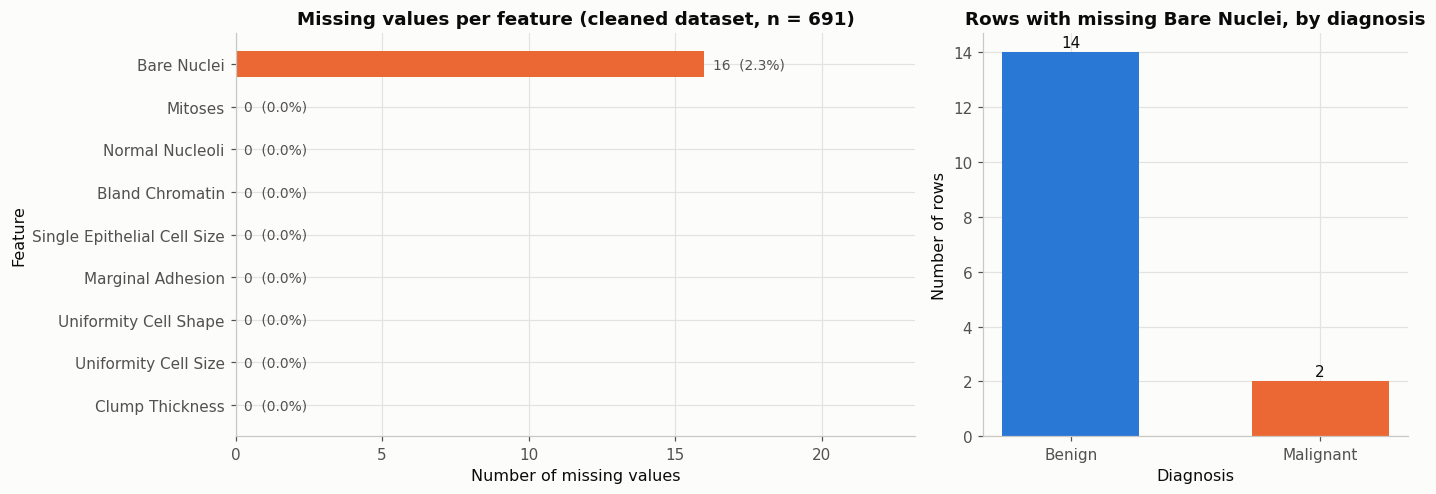

In [20]:
miss_counts = df_clean[FEATURES].isna().sum()
miss_pct = df_clean[FEATURES].isna().mean() * 100
order = miss_counts.sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
colors = [MALIGNANT_C if miss_counts[f] > 0 else "#c9c8c2" for f in order]
ax.barh([LABELS[f] for f in order], miss_counts[order], color=colors, height=0.6)
for i, f in enumerate(order):
    ax.text(miss_counts[f] + 0.3, i, f"{miss_counts[f]}  ({miss_pct[f]:.1f}%)", va="center", fontsize=9, color=INK2)
ax.set_title("Missing values per feature (cleaned dataset, n = 691)")
ax.set_xlabel("Number of missing values")
ax.set_ylabel("Feature")
ax.set_xlim(0, max(miss_counts.max() * 1.45, 1))

ax = axes[1]
miss_by_class = (df_clean.loc[df_clean["Bare_Nuclei"].isna(), TARGET_COL]
                 .map({2: "Benign", 4: "Malignant"}).value_counts().reindex(["Benign", "Malignant"], fill_value=0))
ax.bar(miss_by_class.index, miss_by_class.values, color=[BENIGN_C, MALIGNANT_C], width=0.55)
for i, v in enumerate(miss_by_class.values):
    ax.text(i, v + 0.2, str(v), ha="center", fontsize=10)
ax.set_title("Rows with missing Bare Nuclei, by diagnosis")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of rows")
fig.tight_layout()
save_fig(fig, "01_missing_values")
plt.show()

**Interpretation.** Missingness is confined to a single feature (`Bare_Nuclei`, 16 values ≈ 2.3 %); the other eight features are complete. 14 of the 16 incomplete rows are benign (87.5 % vs 65.6 % overall). With only 16 rows this is weak evidence that missingness is related to the diagnosis, and because so little data is affected, a simple median imputation fitted on the training data is adequate. (Adding a "was missing" indicator feature is listed as a possible extension.)

## 3.2 Target class distribution (count plot)

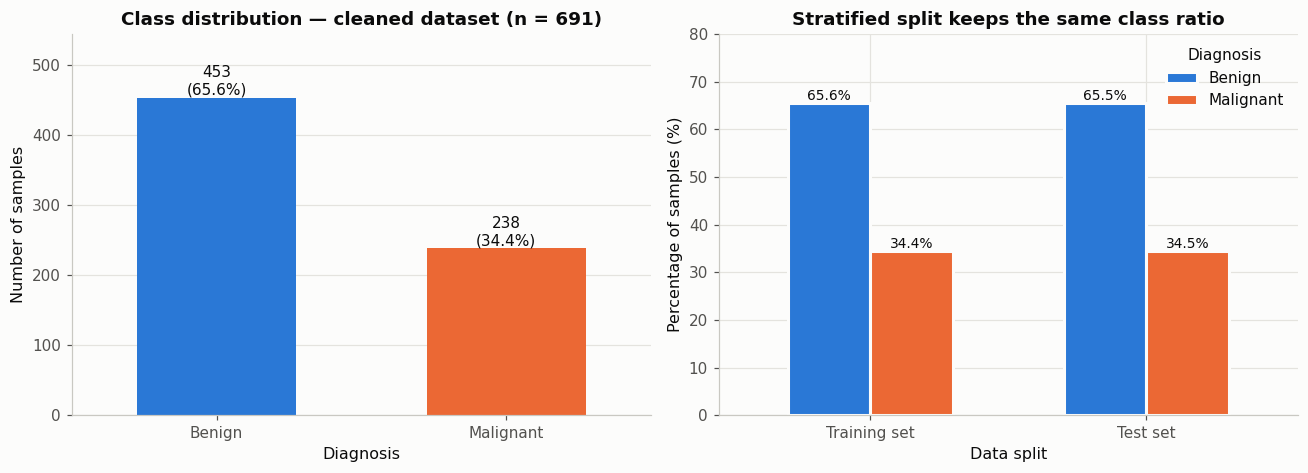

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
diag_all = df_clean[TARGET_COL].map({2: "Benign", 4: "Malignant"})
ax = sns.countplot(x=diag_all, order=["Benign", "Malignant"], hue=diag_all, palette=CLASS_PALETTE,
                   legend=False, width=0.55, saturation=1, ax=axes[0])
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{int(h)}\n({h / len(diag_all):.1%})", (p.get_x() + p.get_width() / 2, h),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Class distribution — cleaned dataset (n = 691)")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of samples")
ax.set_ylim(0, diag_all.value_counts().max() * 1.2)

ax = axes[1]
props = pd.DataFrame({
    "Training set": y_train.map({0: "Benign", 1: "Malignant"}).value_counts(normalize=True),
    "Test set": y_test.map({0: "Benign", 1: "Malignant"}).value_counts(normalize=True),
}).T * 100
props[["Benign", "Malignant"]].plot(kind="bar", ax=ax, color=[BENIGN_C, MALIGNANT_C], width=0.6, rot=0,
                                    edgecolor=SURFACE, linewidth=2)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", fontsize=9)
ax.set_title("Stratified split keeps the same class ratio")
ax.set_xlabel("Data split")
ax.set_ylabel("Percentage of samples (%)")
ax.set_ylim(0, 80)
ax.legend(title="Diagnosis", loc="upper right")
fig.tight_layout()
save_fig(fig, "02_class_distribution")
plt.show()

**Interpretation.** About two thirds of samples are benign and one third malignant. The imbalance is moderate (≈ 1.9 : 1), not severe, so resampling is unnecessary; instead we (a) stratify the split and the CV folds, (b) report recall, F1 and ROC-AUC alongside accuracy, and (c) let `class_weight="balanced"` compete as a hyperparameter. A trivial "always benign" model would already reach ≈ 65.5 % accuracy, which is the baseline every model must clearly beat.

## 3.3 Feature distributions (histograms)

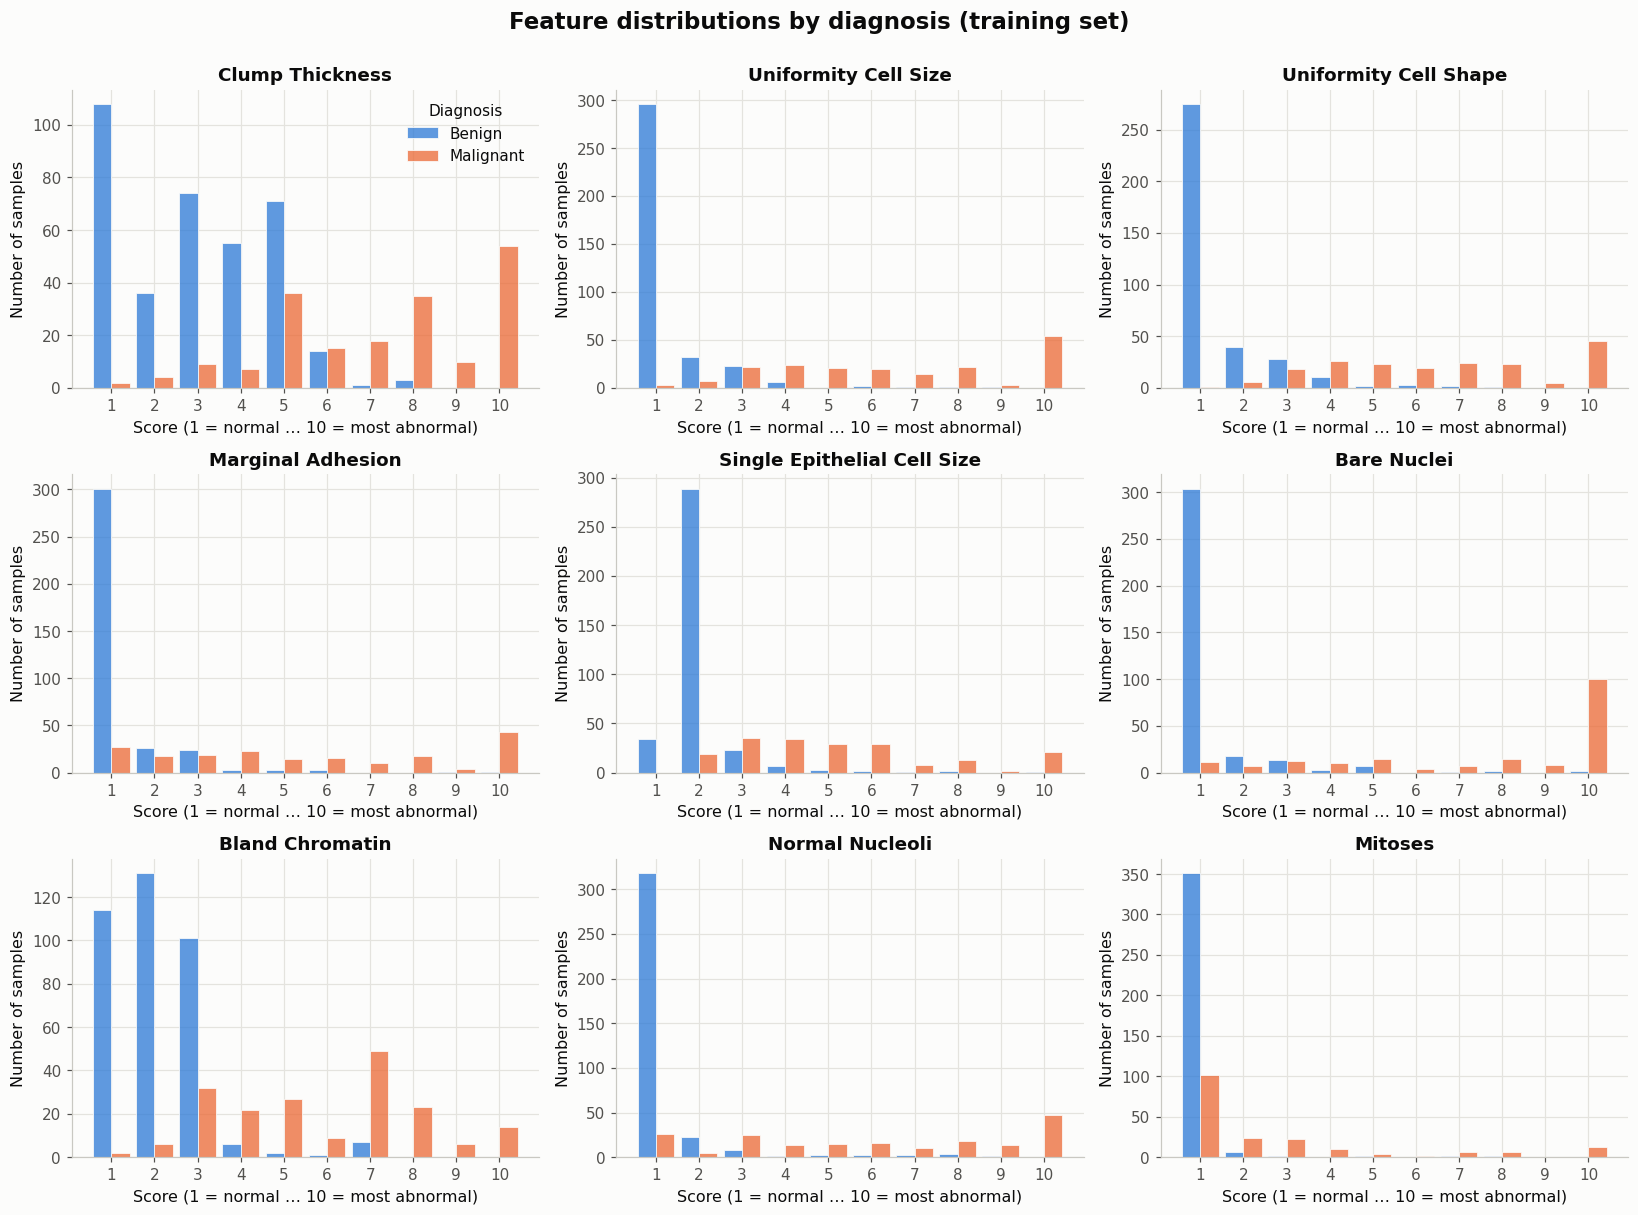

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, feat in zip(axes.ravel(), FEATURES):
    sns.histplot(data=train_df, x=feat, hue="Diagnosis", palette=CLASS_PALETTE, discrete=True,
                 multiple="dodge", shrink=0.85, ax=ax, edgecolor=SURFACE, linewidth=0.5,
                 hue_order=["Benign", "Malignant"])
    ax.set_title(LABELS[feat])
    ax.set_xlabel("Score (1 = normal … 10 = most abnormal)")
    ax.set_ylabel("Number of samples")
    ax.set_xticks(range(1, 11))
    if ax is not axes[0, 0]:
        ax.get_legend().remove()
fig.suptitle("Feature distributions by diagnosis (training set)", fontsize=15, fontweight="bold", y=1.0)
fig.tight_layout()
save_fig(fig, "03_histograms")
plt.show()

**Interpretation.** The two classes occupy almost opposite ends of the scale: benign samples are concentrated at scores 1–3, while malignant samples spread across 3–10. `Uniformity of Cell Size`, `Uniformity of Cell Shape` and `Bare Nuclei` show the clearest separation (benign ≈ almost always 1–2). `Mitoses` is the weakest: most samples of *both* classes score 1, so on its own it separates poorly. All distributions are discrete and skewed, confirming the use of the median for imputation.

## 3.4 Boxplots — comparing distributions and spotting outliers

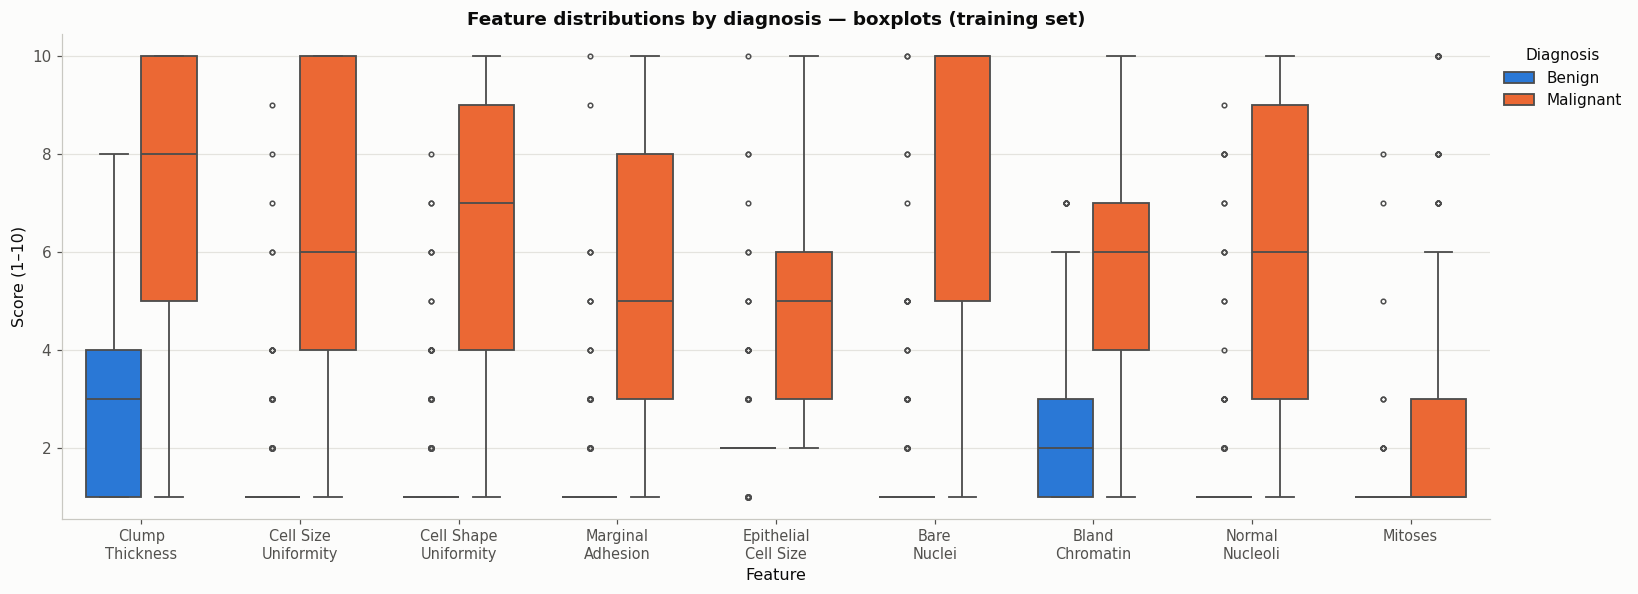

In [23]:
long_df = train_df.melt(id_vars="Diagnosis", value_vars=FEATURES, var_name="Feature", value_name="Score")
long_df["Feature"] = long_df["Feature"].map(LABELS)

fig, ax = plt.subplots(figsize=(15, 5.5))
sns.boxplot(data=long_df, x="Feature", y="Score", hue="Diagnosis", palette=CLASS_PALETTE, saturation=1,
            hue_order=["Benign", "Malignant"], width=0.7, linewidth=1.2, fliersize=3, ax=ax)
ax.set_title("Feature distributions by diagnosis — boxplots (training set)")
ax.set_xlabel("Feature")
ax.set_ylabel("Score (1–10)")
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels([SHORT[f] for f in FEATURES], fontsize=9.5)
ax.legend(title="Diagnosis", loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
save_fig(fig, "04_boxplots")
plt.show()

In [24]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_table = pd.DataFrame({
    "IQR outliers (all)": X_train[FEATURES].apply(iqr_outliers),
    "IQR outliers (benign only)": X_train.loc[y_train == 0, FEATURES].apply(iqr_outliers),
    "IQR outliers (malignant only)": X_train.loc[y_train == 1, FEATURES].apply(iqr_outliers),
})
outlier_table["% of training rows"] = (outlier_table["IQR outliers (all)"] / len(X_train) * 100).round(1)
outlier_table

,IQR outliers (all),IQR outliers (benign only),IQR outliers (malignant only),% of training rows
Clump_Thickness,0,0,0,0.0
Uniformity_Cell_Size,0,66,0,0.0
Uniformity_Cell_Shape,0,87,0,0.0
Marginal_Adhesion,77,61,0,13.9
Single_Epithelial_Cell_Size,39,73,0,7.1
Bare_Nuclei,0,46,0,0.0
Bland_Chromatin,43,7,0,7.8
Normal_Nucleoli,62,44,0,11.2
Mitoses,99,11,25,17.9


**Interpretation.** For every feature except `Mitoses`, the malignant box sits clearly above the benign box — the medians differ by several points. The 1.5·IQR rule flags many "outliers", especially among benign samples (whose boxes are squeezed at 1) and in `Mitoses`, but these are **not errors**: every value is a legitimate score between 1 and 10 assigned by a cytologist, and the high values are exactly the abnormal cells we need the model to learn from. Removing them would delete clinically important information, so **outliers are kept**. (Tree-based models are insensitive to them, and standardization keeps them from dominating distance-based models.)

## 3.5 Correlation heatmap

The features are ordinal, so we use **Spearman rank correlation**, which measures monotonic association without assuming linearity. The target (`Malignant` = 1) is included to show each feature's association with the diagnosis.

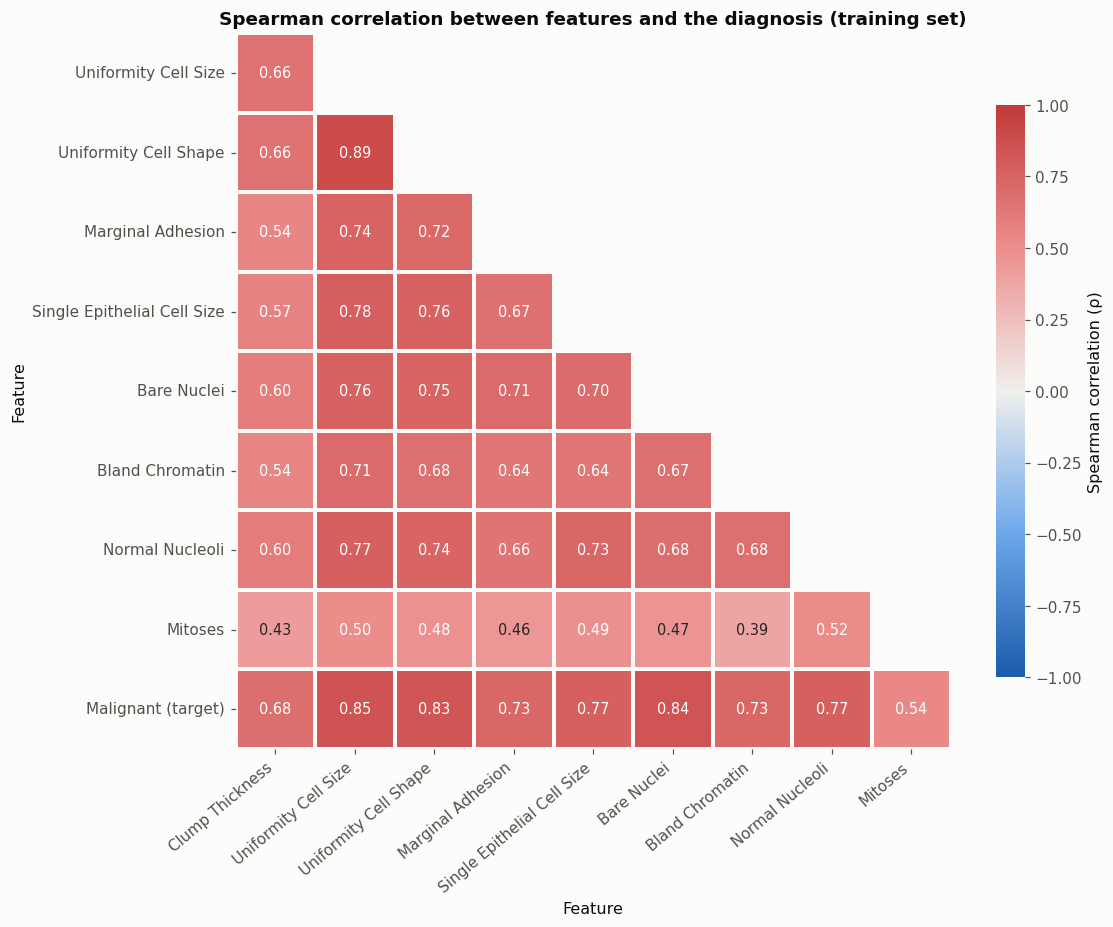

Correlation with malignancy (Spearman ρ):
Uniformity_Cell_Size           0.848
Bare_Nuclei                    0.839
Uniformity_Cell_Shape          0.833
Normal_Nucleoli                0.768
Single_Epithelial_Cell_Size    0.767
Bland_Chromatin                0.728
Marginal_Adhesion              0.727
Clump_Thickness                0.682
Mitoses                        0.538


In [25]:
corr = train_df.assign(Malignant=y_train)[FEATURES + ["Malignant"]].corr(method="spearman")
# Lower triangle without the trivial diagonal (ρ = 1 of each feature with itself)
corr_plot = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(corr_plot, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(corr_plot, mask=mask, cmap=DIV_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 9.5}, linewidths=1.5, linecolor=SURFACE, square=True,
            cbar_kws={"label": "Spearman correlation (ρ)", "shrink": 0.8},
            xticklabels=[LABELS.get(c, c) for c in corr_plot.columns],
            yticklabels=[LABELS.get(c, "Malignant (target)") for c in corr_plot.index], ax=ax)
ax.set_title("Spearman correlation between features and the diagnosis (training set)")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fig.tight_layout()
save_fig(fig, "05_correlation_heatmap")
plt.show()

target_corr = corr["Malignant"].drop("Malignant").sort_values(ascending=False)
print("Correlation with malignancy (Spearman ρ):")
print(target_corr.round(3).to_string())

**Interpretation.** Every feature is **positively** correlated with malignancy — higher abnormality scores mean a higher chance of cancer, consistent with the medical meaning. `Uniformity of Cell Size` (ρ ≈ 0.85), `Bare Nuclei` (≈ 0.84) and `Uniformity of Cell Shape` (≈ 0.83) are the strongest individual predictors. The two uniformity features are also very strongly correlated with **each other** (ρ ≈ 0.89) → they carry overlapping information (multicollinearity). This is not a problem for prediction with regularised models, trees or SVMs, but it means feature-importance scores may be shared between them. `Mitoses` has the weakest relationship with everything.

## 3.6 Before vs after standardization

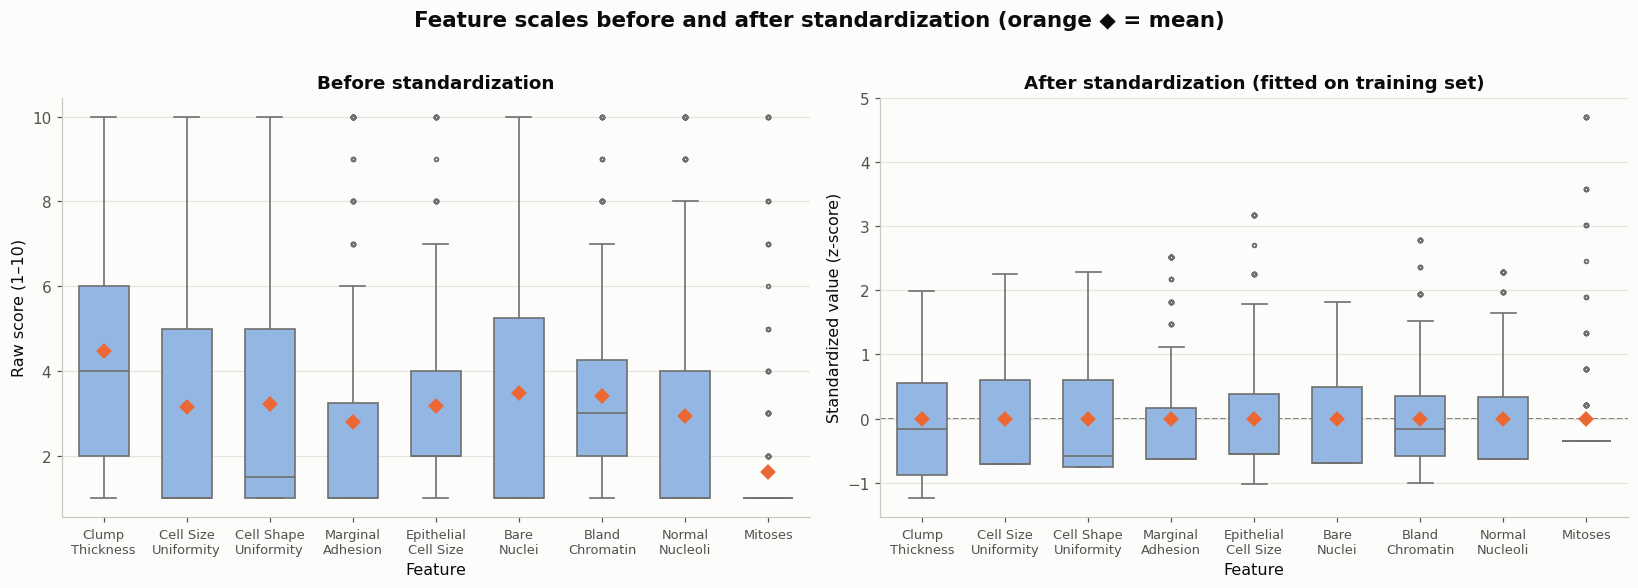

In [26]:
raw_long = X_train_imp.melt(var_name="Feature", value_name="Value").assign(Stage="Before (raw scores)")
std_long = X_train_scaled.melt(var_name="Feature", value_name="Value").assign(Stage="After (z-scores)")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=False)
for ax, data, title, ylabel in [
    (axes[0], raw_long, "Before standardization", "Raw score (1–10)"),
    (axes[1], std_long, "After standardization (fitted on training set)", "Standardized value (z-score)"),
]:
    sns.boxplot(data=data, x="Feature", y="Value", color="#86b6ef", width=0.6, linewidth=1.1,
                fliersize=2.5, ax=ax)
    sns.pointplot(data=data, x="Feature", y="Value", estimator="mean", errorbar=None, color=MALIGNANT_C,
                  linestyle="none", markers="D", markersize=5, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Feature")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(FEATURES)))
    ax.set_xticklabels([SHORT[f] for f in FEATURES], fontsize=8.5)
axes[1].axhline(0, color=INK2, lw=1, ls="--", zorder=0)
fig.suptitle("Feature scales before and after standardization (orange ◆ = mean)", fontsize=14,
             fontweight="bold", y=1.02)
fig.tight_layout()
save_fig(fig, "06_standardization_boxplots")
plt.show()

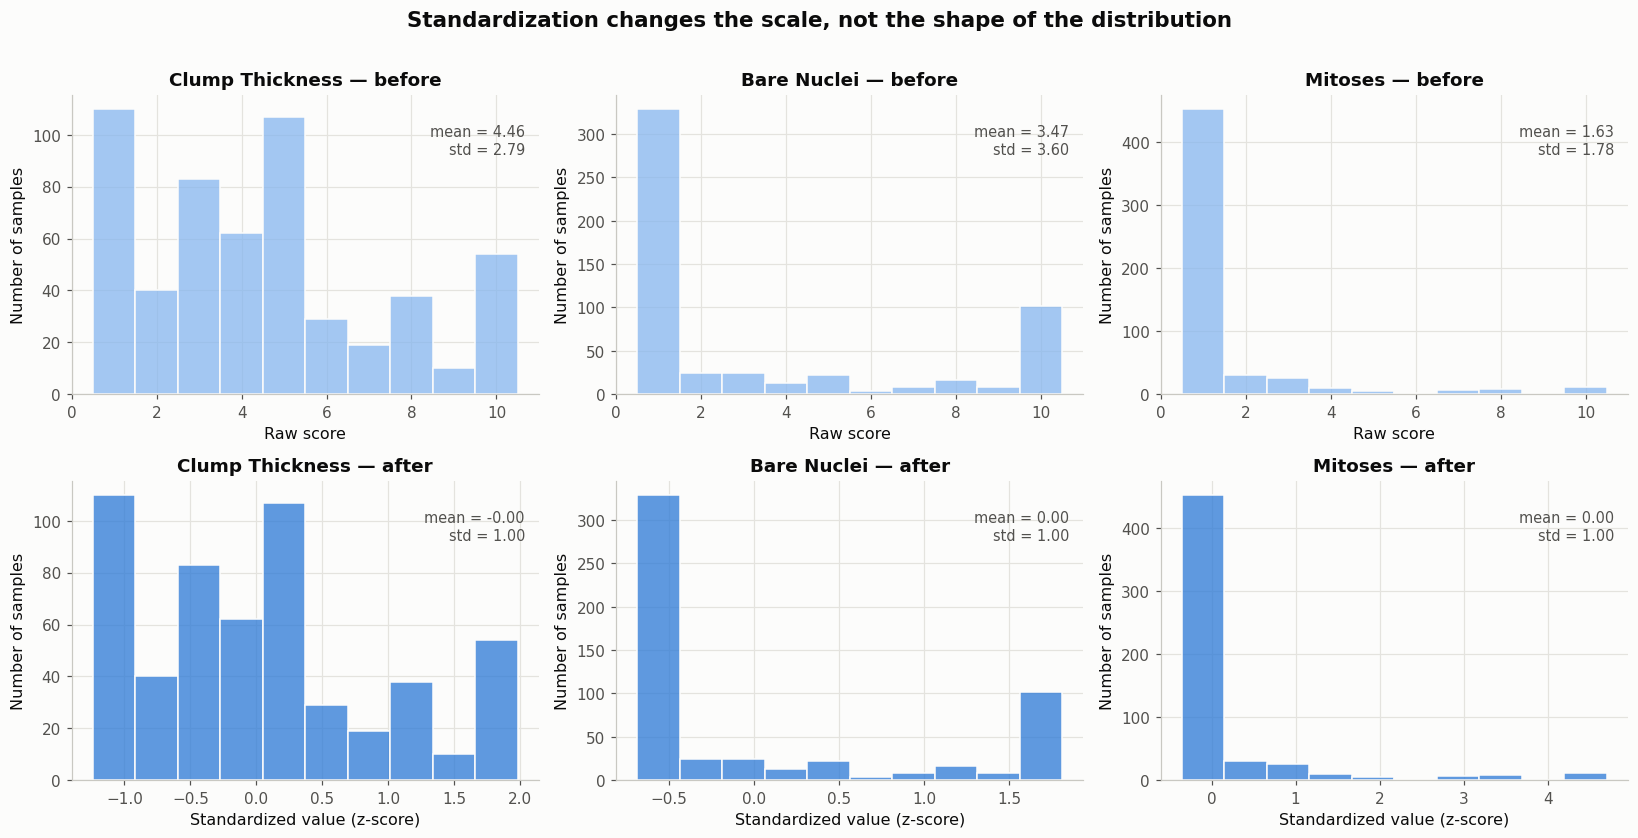

In [27]:
show_feats = ["Clump_Thickness", "Bare_Nuclei", "Mitoses"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for j, feat in enumerate(show_feats):
    sns.histplot(X_train_imp[feat], discrete=True, color="#86b6ef", edgecolor=SURFACE, ax=axes[0, j])
    axes[0, j].set_title(f"{LABELS[feat]} — before")
    axes[0, j].set_xlabel("Raw score")
    axes[0, j].set_ylabel("Number of samples")
    axes[0, j].text(0.97, 0.9, f"mean = {X_train_imp[feat].mean():.2f}\nstd = {X_train_imp[feat].std(ddof=0):.2f}",
                    transform=axes[0, j].transAxes, ha="right", va="top", fontsize=9.5, color=INK2)
    sns.histplot(X_train_scaled[feat], bins=10, color=BENIGN_C, edgecolor=SURFACE, ax=axes[1, j])
    axes[1, j].set_title(f"{LABELS[feat]} — after")
    axes[1, j].set_xlabel("Standardized value (z-score)")
    axes[1, j].set_ylabel("Number of samples")
    axes[1, j].text(0.97, 0.9, f"mean = {X_train_scaled[feat].mean():.2f}\nstd = {X_train_scaled[feat].std(ddof=0):.2f}",
                    transform=axes[1, j].transAxes, ha="right", va="top", fontsize=9.5, color=INK2)
fig.suptitle("Standardization changes the scale, not the shape of the distribution", fontsize=14,
             fontweight="bold", y=1.01)
fig.tight_layout()
save_fig(fig, "07_standardization_histograms")
plt.show()

**Interpretation.** Before scaling, features had different means (≈ 1.6 for `Mitoses` vs ≈ 4.4 for `Clump Thickness`) and spreads. After standardization every feature is centred at 0 with standard deviation 1, so no feature dominates distance calculations in KNN/SVM or gradient updates in the neural network. The histograms show that **standardization is a linear shift and rescale**: the shape (including skewness) is unchanged — only the axis moves.

## 3.7 Bonus EDA — 2-D PCA projection

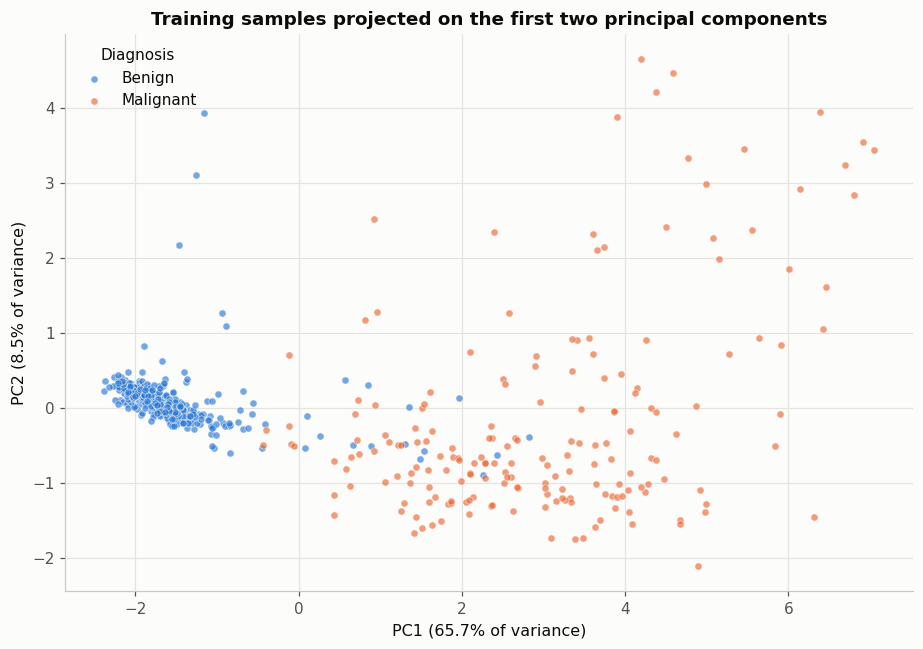

In [28]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_scaled)
pcs = pca.transform(X_train_scaled)
rng_jit = np.random.default_rng(RANDOM_STATE)
pcs_j = pcs + rng_jit.normal(0, 0.05, pcs.shape)   # tiny jitter: many samples share identical scores

fig, ax = plt.subplots(figsize=(8.5, 6))
for label, name in [(0, "Benign"), (1, "Malignant")]:
    m = (y_train == label).to_numpy()
    ax.scatter(pcs_j[m, 0], pcs_j[m, 1], s=22, alpha=0.65, color=CLASS_PALETTE[name], label=name,
               edgecolor=SURFACE, linewidth=0.5)
ax.set_title("Training samples projected on the first two principal components")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
ax.legend(title="Diagnosis")
fig.tight_layout()
save_fig(fig, "08_pca_projection")
plt.show()

**Interpretation.** The first principal component alone explains roughly two thirds of the variance and almost perfectly separates the two classes, with only a small overlap region. This tells us before any modelling that (1) the classes are close to *linearly separable*, so even simple models should perform very well, and (2) the hard cases are the few samples in the overlap zone — that is where the five algorithms will differ.

---
# Task 4 — Model Implementation & Hyperparameter Tuning

## 4.1 The five algorithms

| Algorithm | How it works | Key hyperparameters tuned | Strengths / weaknesses |
|---|---|---|---|
| **K-Nearest Neighbors (KNN)** | Stores the training data; a new sample gets the majority label of its *k* closest neighbours (distance-based). | `n_neighbors` (k), `weights`, distance metric `p` (Manhattan / Euclidean) | Simple, no training; needs scaling, slow on large data |
| **Decision Tree (DT)** | Learns a sequence of if/else splits on features that best separate the classes (Gini / entropy). | `max_depth`, `min_samples_leaf`, `criterion`, `class_weight` | Highly interpretable; prone to overfitting when deep |
| **Random Forest (RF)** | An ensemble of many decision trees trained on bootstrap samples with random feature subsets; predictions are averaged (bagging). | `max_depth`, `max_features`, `min_samples_leaf`, `class_weight` | Robust, low variance; less interpretable than one tree |
| **Artificial Neural Network (ANN)** | A multi-layer perceptron: layers of neurons with non-linear activations, trained by back-propagation (Adam). | hidden layers, `activation`, L2 penalty `alpha` | Learns complex patterns; needs scaling, many settings |
| **Support Vector Machine (SVM)** | Finds the decision boundary with the **maximum margin** between classes; kernels allow non-linear boundaries. | `kernel` (linear / RBF), `C`, `gamma`, `class_weight` | Excellent on small/medium data; needs scaling |

## 4.2 Tuning strategy

* **Method:** exhaustive `GridSearchCV` inside the leakage-free pipeline.
* **Validation:** **10-fold stratified cross-validation on the training set only** (each fold keeps the 65/35 class ratio).
* **Tuning objective:** **F1-score of the malignant class** — it balances precision and recall for the class we care most about and, unlike accuracy, is not inflated by the majority class. All five metrics are recorded for every candidate.

In [ ]:
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}
REFIT_METRIC = "f1"

search_spaces = {
    "KNN": (KNeighborsClassifier(), {
        "model__n_neighbors": list(range(1, 32, 2)),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],                                                                # 1 = Manhattan, 2 = Euclidean
    }),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        "model__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
        "model__min_samples_leaf": [1, 2, 4, 8, 16],
        "model__criterion": ["gini", "entropy"],
        "model__class_weight": [None, "balanced"],
    }),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1), {
        "model__max_depth": [None, 4, 8],
        "model__max_features": [2, 3, 5],
        "model__min_samples_leaf": [1, 3],
        "model__class_weight": [None, "balanced"],
    }),
    "ANN (MLP)": (MLPClassifier(max_iter=2000, random_state=RANDOM_STATE), {
        "model__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16)],
        "model__activation": ["relu", "tanh"],
        "model__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1.0],
    }),
    "SVM": (SVC(random_state=RANDOM_STATE), [
        {"model__kernel": ["linear"], "model__C": [0.01, 0.1, 1, 10, 100],
         "model__class_weight": [None, "balanced"]},
        {"model__kernel": ["rbf"], "model__C": [0.1, 1, 10, 100],
         "model__gamma": ["scale", 0.001, 0.01, 0.1, 1], "model__class_weight": [None, "balanced"]},
    ]),
}

**Design notes.** For Random Forest, `n_estimators` is fixed at 300 rather than tuned: adding trees never makes a forest worse, it only costs time, so it is not a real trade-off parameter. The SVM uses its decision function to compute ROC-AUC (no probability calibration needed during tuning).

In [30]:
searches, tuning_rows = {}, []
for name, (estimator, grid) in search_spaces.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(make_pipeline(estimator), grid, scoring=SCORING, refit=REFIT_METRIC,
                      cv=CV, n_jobs=-1, return_train_score=True)
    gs.fit(X_train, y_train)
    searches[name] = gs
    i = gs.best_index_
    res = gs.cv_results_
    tuning_rows.append({
        "Model": name,
        "Candidates tried": len(res["params"]),
        "Best hyperparameters": ", ".join(f"{k.replace('model__', '')}={v}" for k, v in gs.best_params_.items()),
        **{f"CV {m}": f"{res[f'mean_test_{m}'][i]:.4f} ± {res[f'std_test_{m}'][i]:.4f}" for m in SCORING},
        "Train F1": round(res["mean_train_f1"][i], 4),
        "Time (s)": round(time.perf_counter() - t0, 1),
    })
    print(f"✓ {name:<14} best CV F1 = {gs.best_score_:.4f}   ({tuning_rows[-1]['Time (s)']} s)")

tuning_table = pd.DataFrame(tuning_rows).set_index("Model")
tuning_table

✓ KNN            best CV F1 = 0.9555   (38.0 s)
✓ Decision Tree  best CV F1 = 0.9371   (63.6 s)
✓ Random Forest  best CV F1 = 0.9615   (232.2 s)
✓ ANN (MLP)      best CV F1 = 0.9557   (190.8 s)
✓ SVM            best CV F1 = 0.9559   (26.9 s)


,Candidates tried,Best hyperparameters,CV accuracy,CV precision,CV recall,CV f1,CV roc_auc,Train F1,Time (s)
Model,,,,,,,,,
KNN,64,"n_neighbors=21, p=2, weights=uniform",0.9692 ± 0.0199,0.9515 ± 0.0464,0.9632 ± 0.0529,0.9555 ± 0.0293,0.9900 ± 0.0108,0.9564,38.0
Decision Tree,160,"class_weight=balanced, criterion=gini, max_dep...",0.9565 ± 0.0185,0.9300 ± 0.0376,0.9474 ± 0.0526,0.9371 ± 0.0273,0.9633 ± 0.0296,0.9598,63.6
Random Forest,36,"class_weight=None, max_depth=8, max_features=3...",0.9728 ± 0.0122,0.9463 ± 0.0379,0.9789 ± 0.0258,0.9615 ± 0.0163,0.9917 ± 0.0082,1.0000,232.2
ANN (MLP),40,"activation=relu, alpha=0.1, hidden_layer_sizes...",0.9692 ± 0.0182,0.9505 ± 0.0413,0.9632 ± 0.0411,0.9557 ± 0.0263,0.9949 ± 0.0052,0.9631,190.8
SVM,50,"C=0.1, class_weight=balanced, gamma=0.01, kern...",0.9692 ± 0.0199,0.9459 ± 0.0435,0.9684 ± 0.0421,0.9559 ± 0.0287,0.9945 ± 0.0048,0.9558,26.9


## 4.3 What the tuning revealed

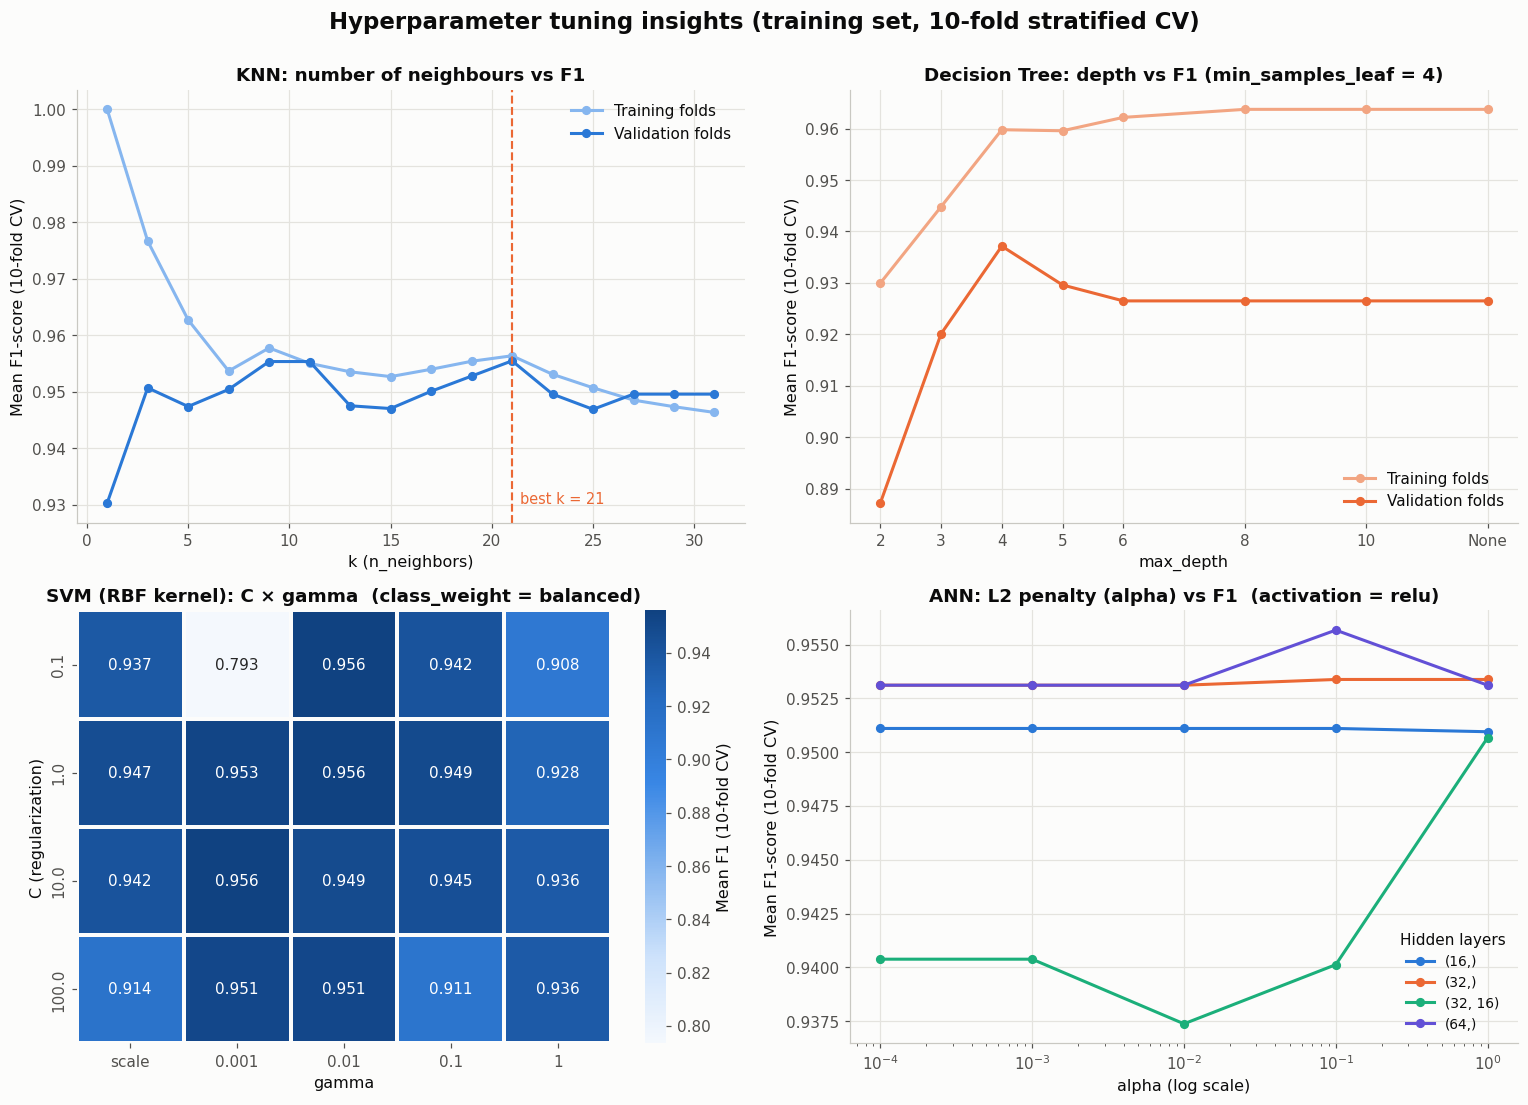

In [31]:
def cv_frame(name):
    res = searches[name].cv_results_
    frame = pd.DataFrame(res["params"])
    frame.columns = [c.replace("model__", "") for c in frame.columns]
    frame["val_f1"], frame["train_f1"] = res["mean_test_f1"], res["mean_train_f1"]
    return frame

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) KNN — effect of k
ax = axes[0, 0]
knn_df = cv_frame("KNN")
bp = searches["KNN"].best_params_
sub = knn_df[(knn_df["weights"] == bp["model__weights"]) & (knn_df["p"] == bp["model__p"])]
ax.plot(sub["n_neighbors"], sub["train_f1"], marker="o", ms=5, color="#86b6ef", label="Training folds")
ax.plot(sub["n_neighbors"], sub["val_f1"], marker="o", ms=5, color=BENIGN_C, label="Validation folds")
ax.axvline(bp["model__n_neighbors"], color=MALIGNANT_C, ls="--", lw=1.4)
ax.text(bp["model__n_neighbors"] + 0.4, sub["val_f1"].min(), f"best k = {bp['model__n_neighbors']}", color=MALIGNANT_C, fontsize=9.5)
ax.set_title("KNN: number of neighbours vs F1")
ax.set_xlabel("k (n_neighbors)")
ax.set_ylabel("Mean F1-score (10-fold CV)")
ax.legend()

# (b) Decision tree — effect of depth (overfitting)
ax = axes[0, 1]
dt_df = cv_frame("Decision Tree")
bp = searches["Decision Tree"].best_params_
sub = dt_df[(dt_df["min_samples_leaf"] == bp["model__min_samples_leaf"]) & (dt_df["criterion"] == bp["model__criterion"]) &
            (dt_df["class_weight"].astype(str) == str(bp["model__class_weight"]))].copy()
sub["depth"] = sub["max_depth"].fillna(0).astype(int).replace(0, 12)
sub = sub.sort_values("depth")
ax.plot(sub["depth"], sub["train_f1"], marker="o", ms=5, color="#f2a582", label="Training folds")
ax.plot(sub["depth"], sub["val_f1"], marker="o", ms=5, color=MALIGNANT_C, label="Validation folds")
ax.set_xticks([2, 3, 4, 5, 6, 8, 10, 12])
ax.set_xticklabels(["2", "3", "4", "5", "6", "8", "10", "None"])
ax.set_title(f"Decision Tree: depth vs F1 (min_samples_leaf = {bp['model__min_samples_leaf']})")
ax.set_xlabel("max_depth")
ax.set_ylabel("Mean F1-score (10-fold CV)")
ax.legend()

# (c) SVM RBF — C × gamma heatmap
ax = axes[1, 0]
svm_df = cv_frame("SVM")
bp = searches["SVM"].best_params_
rbf = svm_df[(svm_df["kernel"] == "rbf") & (svm_df["class_weight"].astype(str) == str(bp["model__class_weight"]))]
pivot = rbf.pivot_table(index="C", columns="gamma", values="val_f1", aggfunc="mean")
pivot = pivot[[c for c in ["scale", 0.001, 0.01, 0.1, 1] if c in pivot.columns]]
sns.heatmap(pivot, annot=True, fmt=".3f", cmap=SEQ_CMAP, cbar_kws={"label": "Mean F1 (10-fold CV)"},
            linewidths=1.5, linecolor=SURFACE, ax=ax)
ax.set_title(f"SVM (RBF kernel): C × gamma  (class_weight = {bp['model__class_weight']})")
ax.set_xlabel("gamma")
ax.set_ylabel("C (regularization)")
ax.grid(False)

# (d) ANN — effect of L2 regularization alpha
ax = axes[1, 1]
mlp_df = cv_frame("ANN (MLP)")
best_act = searches["ANN (MLP)"].best_params_["model__activation"]
layer_colors = iter(["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"])
for hl, g in mlp_df[mlp_df["activation"] == best_act].groupby("hidden_layer_sizes"):
    g = g.sort_values("alpha")
    ax.plot(g["alpha"], g["val_f1"], marker="o", ms=5, color=next(layer_colors), label=f"{hl}")
ax.set_xscale("log")
ax.set_title(f"ANN: L2 penalty (alpha) vs F1  (activation = {searches['ANN (MLP)'].best_params_['model__activation']})")
ax.set_xlabel("alpha (log scale)")
ax.set_ylabel("Mean F1-score (10-fold CV)")
ax.legend(title="Hidden layers", fontsize=9)

fig.suptitle("Hyperparameter tuning insights (training set, 10-fold stratified CV)", fontsize=15, fontweight="bold", y=1.0)
fig.tight_layout()
save_fig(fig, "09_tuning_insights")
plt.show()

**Interpretation.**
* **KNN** — with *k* = 1 the model memorises the training folds (training F1 = 1.0) but has the lowest validation F1 (≈ 0.93): high variance. From *k* ≈ 9 onward the validation F1 plateaus around 0.95–0.956; the best value is **k = 21**, where training and validation scores almost coincide (no overfitting).
* **Decision Tree** — the classic **overfitting** picture: training F1 keeps rising with depth, while validation F1 peaks at **depth 4** (0.940) and then falls to ≈ 0.93 — the growing gap between the curves is overfitting. Limiting complexity (depth 4, at least 4 samples per leaf) is essential for a single tree.
* **SVM** — F1 is stable (≈ 0.94–0.956) over a wide band of `C`/`gamma`. It drops when the boundary is too simple (`C = 0.1, γ = 0.001` → F1 0.79, underfitting) or too flexible (large `C` with large `γ`). The selected setting is a smooth RBF boundary (`C = 0.1, γ = 0.01`).
* **ANN** — the network size matters more than the penalty: one hidden layer of 32–64 neurons works best, while the deeper (32, 16) network is consistently weaker. A moderate L2 penalty (`alpha = 0.1`) gives the best score.

The tuned Random Forest reaches training F1 = 1.0 (its trees are deep), yet its validation F1 is the highest of the 10-fold search — averaging many decorrelated trees controls the variance that hurts the single tree.

## 4.4 The tuned Decision Tree (interpretability)

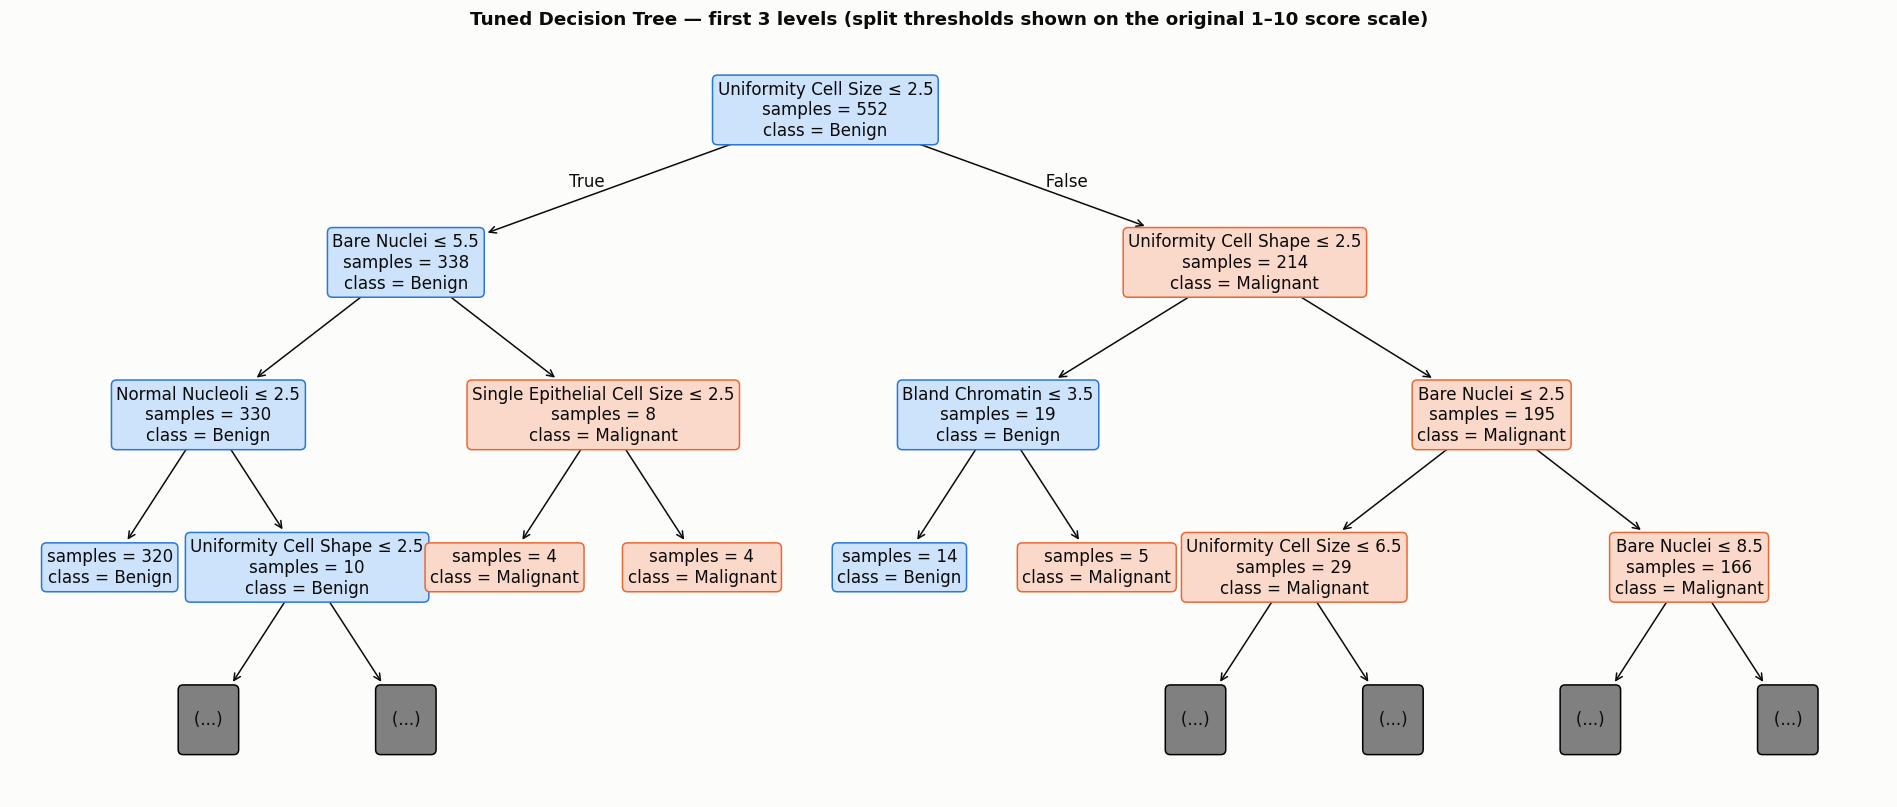

In [32]:
import re

best_dt = searches["Decision Tree"].best_estimator_
dt_scaler, dt_model = best_dt.named_steps["scaler"], best_dt.named_steps["model"]
fig, ax = plt.subplots(figsize=(22, 9))
artists = plot_tree(dt_model, feature_names=[LABELS[f] for f in FEATURES], class_names=["Benign", "Malignant"],
                    filled=True, rounded=True, impurity=False, fontsize=11, ax=ax, max_depth=3)

# The tree was trained on standardized inputs. Convert each split back to the original 1-10 score
# (raw = z * σ + μ) so the rules are readable, hide the class-weighted "value" line, and recolour by class.
label_to_idx = {LABELS[f]: i for i, f in enumerate(FEATURES)}
for art in artists:
    text = art.get_text()
    lines = [l for l in text.split("\n") if not l.startswith("value")]
    m = re.match(r"^(.*) <= (-?[\d.]+)$", lines[0]) if lines else None
    if m and m.group(1) in label_to_idx:
        i = label_to_idx[m.group(1)]
        lines[0] = f"{m.group(1)} ≤ {float(m.group(2)) * dt_scaler.scale_[i] + dt_scaler.mean_[i]:.1f}"
    art.set_text("\n".join(lines))
    box = art.get_bbox_patch()
    if box is not None and "class =" in text:
        benign = "class = Benign" in text
        box.set_facecolor("#cde2fb" if benign else "#fbd9ca")
        box.set_edgecolor(BENIGN_C if benign else MALIGNANT_C)
ax.set_title("Tuned Decision Tree — first 3 levels (split thresholds shown on the original 1–10 score scale)")
ax.grid(False)
save_fig(fig, "10_decision_tree")
plt.show()

**Interpretation.** The tree's first question is *"Is Uniformity of Cell Size ≤ 2.5?"* — the feature with the highest correlation to malignancy in the EDA. Uniform, small cells lead to the benign branch, where `Bare Nuclei` then catches the few malignant samples. Non-uniform cells lead to the malignant branch, where `Uniformity of Cell Shape` and `Bare Nuclei` refine the decision. These are rules a doctor could follow by hand — the main advantage of a single tree — but, as the test results will show, this simplicity costs accuracy compared with the other models.

---
# Task 5 — Model Evaluation

## 5.1 Evaluation metrics explained (malignant = positive class)

| Metric | Formula | Meaning in this problem |
|---|---|---|
| **Accuracy** | (TP + TN) / all | Share of all diagnoses that are correct. Can be misleading with imbalance (65.5 % by always saying "benign"). |
| **Precision** | TP / (TP + FP) | When the model says *malignant*, how often is it right? Low precision → unnecessary biopsies and anxiety. |
| **Recall (Sensitivity)** | TP / (TP + FN) | Of all truly malignant tumours, how many did we catch? **Most important clinically** — every missed case (FN) is a cancer left untreated. |
| **F1-score** | 2·P·R / (P + R) | Harmonic mean of precision and recall; high only if *both* are high. |
| **ROC-AUC** | Area under the ROC curve | Probability that a random malignant sample receives a higher risk score than a random benign one. Threshold-independent measure of ranking quality (0.5 = random, 1.0 = perfect). |

*TP = malignant predicted malignant, TN = benign predicted benign, FP = benign predicted malignant (false alarm), FN = malignant predicted benign (missed cancer).*

We also report **Specificity** (TN / (TN + FP)) and **MCC** (Matthews correlation coefficient, a balanced single-number summary robust to class imbalance) as extra context.

## 5.2 Model selection on the training set (repeated cross-validation)

The assignment requires that the test set stay separate during model selection. We therefore choose the best model **using cross-validation on the training data only**, and declare the rule **before** looking at the test set:

> **Selection rule.** The best model is the one with the highest **mean F1** over **10-fold × 5-repeat stratified CV** (50 fits per model, same folds for every model). If two models are within 0.005 of each other, prefer the one with higher **recall**, then higher **ROC-AUC**. The test set is then used once to confirm the choice and report final performance.

Repeating the 10-fold CV five times with different shuffles gives 50 scores per model, which reduces the luck of a single fold split.

In [33]:
RCV = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=RANDOM_STATE)
tuned_pipelines = {name: clone(gs.best_estimator_) for name, gs in searches.items()}

rcv_scores = {}
for name, pipe in tuned_pipelines.items():
    out = cross_validate(pipe, X_train, y_train, cv=RCV, scoring=SCORING, n_jobs=-1)
    rcv_scores[name] = {m: out[f"test_{m}"] for m in SCORING}

rcv_table = pd.DataFrame({
    name: {**{f"{m} mean": s[m].mean() for m in SCORING}, **{f"{m} std": s[m].std() for m in SCORING}}
    for name, s in rcv_scores.items()
}).T
cols = ["accuracy mean", "precision mean", "recall mean", "f1 mean", "f1 std", "roc_auc mean"]
rcv_table = rcv_table[cols].sort_values("f1 mean", ascending=False)
rcv_table.round(4)

,accuracy mean,precision mean,recall mean,f1 mean,f1 std,roc_auc mean
ANN (MLP),0.9696,0.9474,0.9674,0.9565,0.0320,0.9939
SVM,0.9685,0.9454,0.9663,0.9548,0.0339,0.9936
Random Forest,0.9681,0.9453,0.9653,0.9543,0.0319,0.9904
KNN,0.9681,0.9518,0.9579,0.9537,0.0386,0.9913
Decision Tree,0.9497,0.9176,0.9411,0.9275,0.0349,0.9642


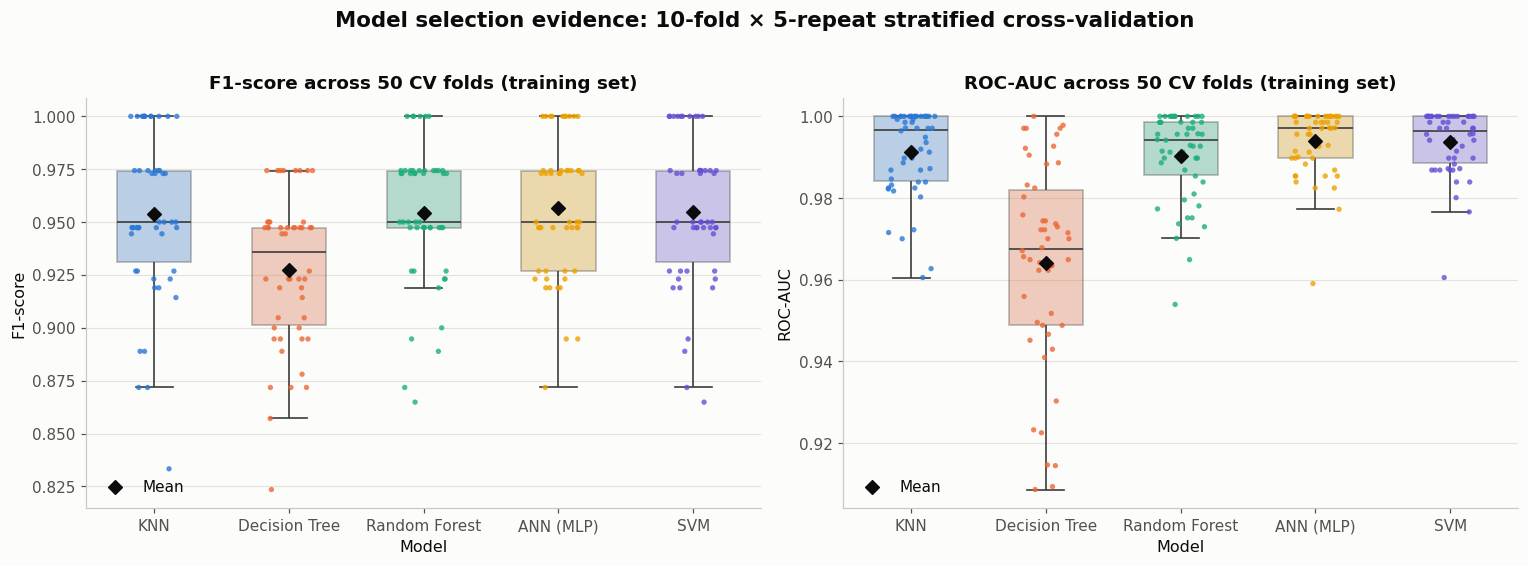

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [(axes[0], "f1", "F1-score"), (axes[1], "roc_auc", "ROC-AUC")]:
    data = pd.DataFrame({n: rcv_scores[n][metric] for n in MODEL_NAMES}).melt(var_name="Model", value_name="Score")
    sns.boxplot(data=data, x="Model", y="Score", hue="Model", palette=MODEL_COLORS, legend=False,
                width=0.55, linewidth=1.1, fliersize=0, boxprops={"alpha": 0.35}, ax=ax)
    sns.stripplot(data=data, x="Model", y="Score", hue="Model", palette=MODEL_COLORS, legend=False,
                  size=3.5, jitter=0.18, alpha=0.8, ax=ax)
    means = data.groupby("Model")["Score"].mean().reindex(MODEL_NAMES)
    ax.scatter(range(5), means.values, marker="D", s=40, color=INK, zorder=5, label="Mean")
    ax.set_title(f"{title} across 50 CV folds (training set)")
    ax.set_xlabel("Model")
    ax.set_ylabel(title)
    ax.legend(loc="lower left")
fig.suptitle("Model selection evidence: 10-fold × 5-repeat stratified cross-validation", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
save_fig(fig, "11_cv_model_selection")
plt.show()

In [35]:
def corrected_resampled_ttest(a, b, n_train, n_test):
    """Nadeau & Bengio (2003) corrected t-test for repeated k-fold CV scores.
    The correction accounts for overlapping training sets between folds, which makes the
    ordinary paired t-test far too optimistic."""
    d = np.asarray(a) - np.asarray(b)
    n = len(d)
    var = d.var(ddof=1)
    if var == 0:
        return d.mean(), 0.0, 1.0
    t = d.mean() / np.sqrt((1 / n + n_test / n_train) * var)
    return d.mean(), t, 2 * stats.t.sf(abs(t), df=n - 1)

# --- apply the pre-declared selection rule ---
ranking = rcv_table.copy()
top_f1 = ranking["f1 mean"].max()
contenders = ranking[ranking["f1 mean"] >= top_f1 - 0.005]
best_name = contenders.sort_values(["recall mean", "roc_auc mean"], ascending=False).index[0]
print(f"Models within 0.005 F1 of the top: {list(contenders.index)}")
print(f"➜ Selected model (by the rule): {best_name}\n")

n_tr_fold, n_te_fold = len(X_train) * 0.9, len(X_train) * 0.1
ttest_rows = []
for name in MODEL_NAMES:
    if name == best_name:
        continue
    diff, t, p = corrected_resampled_ttest(rcv_scores[best_name]["f1"], rcv_scores[name]["f1"], n_tr_fold, n_te_fold)
    ttest_rows.append({"Comparison": f"{best_name} vs {name}", "Mean F1 difference": round(diff, 4),
                       "t": round(t, 3), "p-value": round(p, 4), "Significant at 5%?": "Yes" if p < 0.05 else "No"})
pd.DataFrame(ttest_rows).set_index("Comparison")

Models within 0.005 F1 of the top: ['ANN (MLP)', 'SVM', 'Random Forest', 'KNN']
➜ Selected model (by the rule): ANN (MLP)



,Mean F1 difference,t,p-value,Significant at 5%?
Comparison,,,,
ANN (MLP) vs KNN,0.0028,0.349,0.7286,No
ANN (MLP) vs Decision Tree,0.0290,2.398,0.0203,Yes
ANN (MLP) vs Random Forest,0.0022,0.374,0.7102,No
ANN (MLP) vs SVM,0.0017,0.255,0.8000,No


**Interpretation.**
* Four models form a tight leading group: **ANN 0.9565**, SVM 0.9548, Random Forest 0.9543 and KNN 0.9537 mean F1 — a spread of only 0.003. The **Decision Tree is clearly behind** (0.928) and has the widest spread of ROC-AUC across folds.
* Applying the pre-declared rule, the **ANN (MLP)** is selected: it has the highest mean F1 *and*, among the tied contenders, the highest mean recall (0.967) and ROC-AUC (0.994).
* The corrected resampled t-test confirms what the boxplots suggest: the ANN is **significantly better than the Decision Tree** (p ≈ 0.02), but its advantage over SVM, Random Forest and KNN is **not statistically significant** (p > 0.7). Honest conclusion: four algorithms reach the ceiling of what these nine features allow; the choice among them is made by the transparent rule, not by a dramatic gap.

## 5.3 Final evaluation on the held-out test set

Each tuned pipeline (already refitted by `GridSearchCV` on the full training set) is now evaluated **once** on the 139 untouched test samples.

In [36]:
def positive_scores(model, X_):
    """Continuous risk score for the malignant class: probability if available, otherwise SVM decision value."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)

def evaluate(model, X_, y_):
    y_pred = model.predict(X_)
    scores = positive_scores(model, X_)
    tn, fp, fn, tp = confusion_matrix(y_, y_pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_, y_pred),
        "Precision": precision_score(y_, y_pred, zero_division=0),
        "Recall": recall_score(y_, y_pred),
        "F1-score": f1_score(y_, y_pred),
        "ROC-AUC": roc_auc_score(y_, scores),
        "Specificity": tn / (tn + fp),
        "MCC": matthews_corrcoef(y_, y_pred),
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
    }

final_models = {name: gs.best_estimator_ for name, gs in searches.items()}
test_results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in final_models.items()}).T
test_results = test_results.apply(pd.to_numeric)
test_results.index.name = "Model"
for c in ["TP", "TN", "FP", "FN"]:
    test_results[c] = test_results[c].astype(int)

### Comparison table — all models

In [37]:
comparison = test_results.copy()
comparison.insert(0, "CV F1 (train, 10×5)", rcv_table["f1 mean"].reindex(comparison.index))
comparison["Selected"] = ["★ best" if n == best_name else "" for n in comparison.index]
comparison.to_csv(RESULTS_DIR / "model_comparison.csv", float_format="%.4f")

metric_cols = ["CV F1 (train, 10×5)", "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "Specificity", "MCC"]
(comparison.style
    .format({c: "{:.4f}" for c in metric_cols})
    .highlight_max(subset=metric_cols, props="font-weight:bold; background-color:#cde2fb; color:#0b0b0b")
    .highlight_min(subset=["FN", "FP"], props="font-weight:bold; background-color:#cde2fb; color:#0b0b0b")
    .set_caption("Test-set performance of the five tuned models (malignant = positive class). Best value per column highlighted."))

,"CV F1 (train, 10×5)",Accuracy,Precision,Recall,F1-score,ROC-AUC,Specificity,MCC,TP,TN,FP,FN,Selected
Model,,,,,,,,,,,,,
KNN,0.9537,0.9640,0.9574,0.9375,0.9474,0.9868,0.9780,0.9202,45,89,2,3,
Decision Tree,0.9275,0.9281,0.9318,0.8542,0.8913,0.9655,0.9670,0.8395,41,88,3,7,
Random Forest,0.9543,0.9640,0.9574,0.9375,0.9474,0.9936,0.9780,0.9202,45,89,2,3,
ANN (MLP),0.9565,0.9712,0.9783,0.9375,0.9574,0.9963,0.9890,0.9362,45,90,1,3,★ best
SVM,0.9548,0.9712,0.9583,0.9583,0.9583,0.9959,0.9780,0.9364,46,89,2,2,


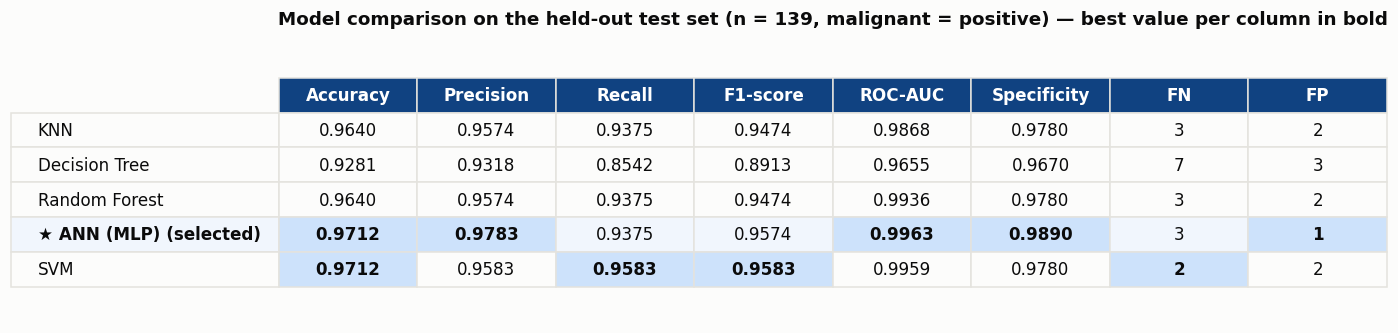

In [38]:
# Same table as a figure for the slides
fig, ax = plt.subplots(figsize=(13, 3.3))
ax.axis("off")
show_cols = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "Specificity", "FN", "FP"]
cell_text = [[f"{comparison.loc[n, c]:.4f}" if c not in ("FN", "FP") else str(int(comparison.loc[n, c]))
              for c in show_cols] for n in comparison.index]
row_labels = [f"★ {n} (selected)" if n == best_name else n for n in comparison.index]
table = ax.table(cellText=cell_text, rowLabels=row_labels, colLabels=show_cols, loc="center", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.9)
# best value per column (lowest for FN/FP) → bold on a blue tint; selected model's row → light tint
best_in_col = {c: (comparison[c].min() if c in ("FN", "FP") else comparison[c].max()) for c in show_cols}
for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor(GRID)
    if r == 0:
        cell.set_facecolor("#104281"); cell.get_text().set_color("white"); cell.get_text().set_weight("bold")
        continue
    model = comparison.index[r - 1]
    cell.set_facecolor("#f1f6fd" if model == best_name else SURFACE)
    if c == -1:
        cell.get_text().set_weight("bold" if model == best_name else "normal")
    elif np.isclose(comparison.loc[model, show_cols[c]], best_in_col[show_cols[c]]):
        cell.set_facecolor("#cde2fb"); cell.get_text().set_weight("bold")
ax.set_title("Model comparison on the held-out test set (n = 139, malignant = positive) — best value per column in bold", pad=12)
save_fig(fig, "12_comparison_table")
plt.show()

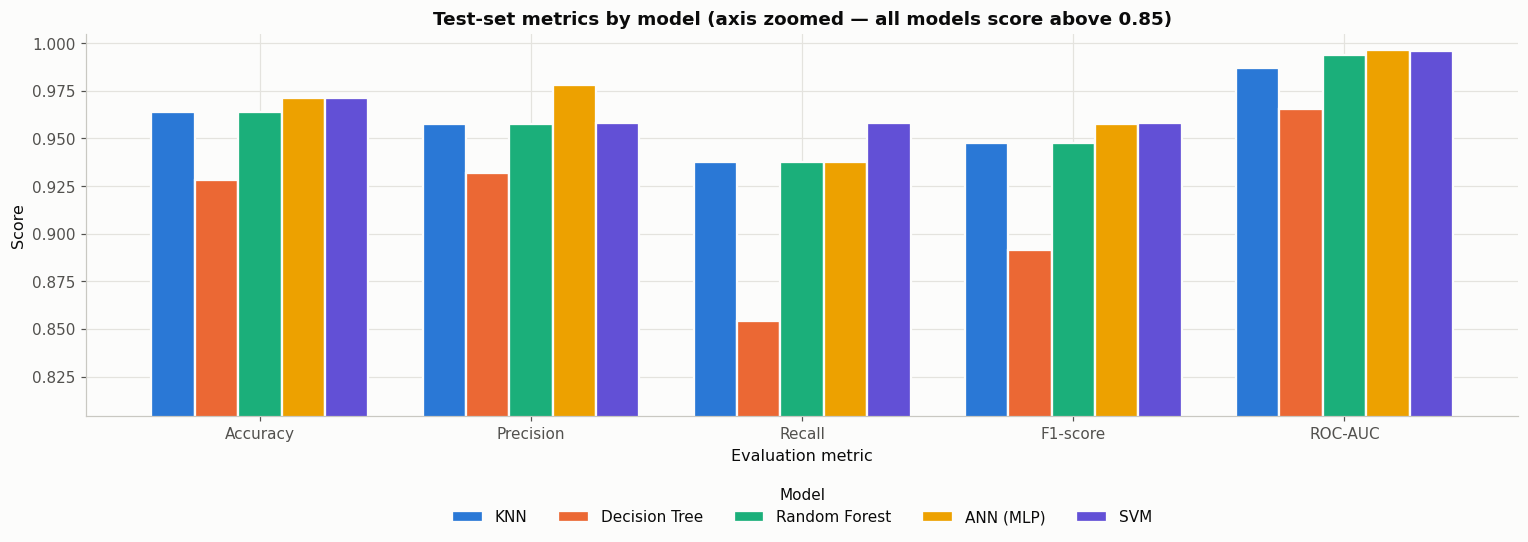

In [39]:
fig, ax = plt.subplots(figsize=(14, 5.2))
plot_metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
x = np.arange(len(plot_metrics))
width = 0.16
for i, name in enumerate(MODEL_NAMES):
    vals = test_results.loc[name, plot_metrics].astype(float).values
    ax.bar(x + (i - 2) * width, vals, width, label=name, color=MODEL_COLORS[name], edgecolor=SURFACE, linewidth=1.5)
ax.set_xticks(x)
ax.set_xticklabels(plot_metrics)
lo = float(test_results[plot_metrics].min().min())
ax.set_ylim(max(0.0, lo - 0.05), 1.005)
ax.set_title("Test-set metrics by model (axis zoomed — all models score above "
             f"{lo:.2f})")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Score")
ax.legend(title="Model", ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.32))
fig.tight_layout()
save_fig(fig, "13_metrics_bar")
plt.show()

## 5.4 Confusion matrices

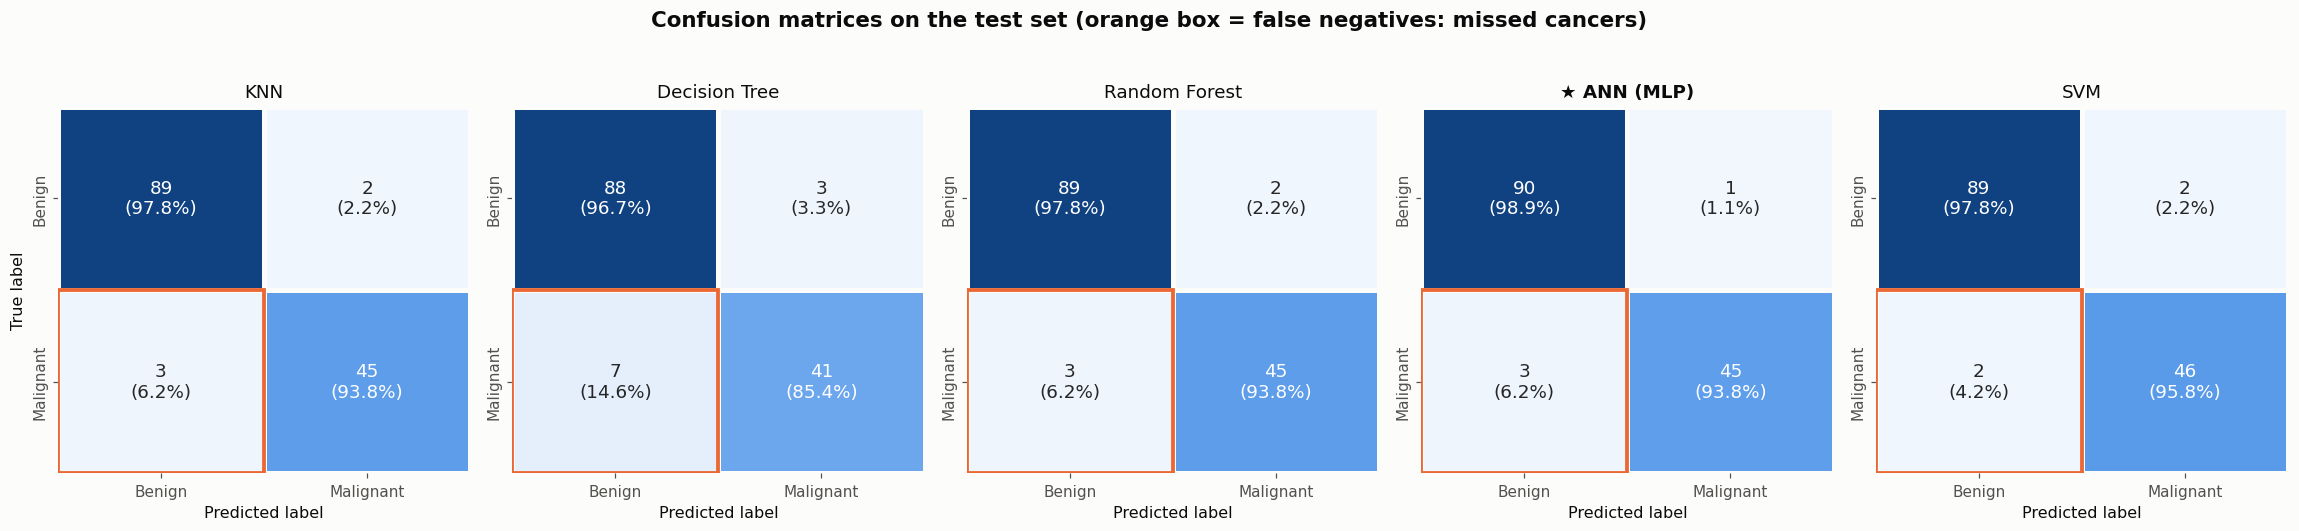

In [40]:
fig, axes = plt.subplots(1, 5, figsize=(21, 4.6))
for ax, name in zip(axes, MODEL_NAMES):
    cm = confusion_matrix(y_test, final_models[name].predict(X_test), labels=[0, 1])
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cm[i, j]}\n({row_pct[i, j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap=SEQ_CMAP, cbar=False, linewidths=2, linecolor=SURFACE,
                xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"],
                annot_kws={"size": 12}, ax=ax, vmin=0, vmax=cm.max())
    ax.set_title(("★ " if name == best_name else "") + name, fontweight="bold" if name == best_name else "normal")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label" if ax is axes[0] else "")
    ax.grid(False)
    ax.add_patch(plt.Rectangle((0, 1), 1, 1, fill=False, edgecolor=MALIGNANT_C, lw=2.5))  # FN cell
fig.suptitle("Confusion matrices on the test set (orange box = false negatives: missed cancers)",
             fontsize=14, fontweight="bold", y=1.04)
fig.tight_layout()
save_fig(fig, "14_confusion_matrices")
plt.show()

**Interpretation.** Rows are the true diagnosis, columns the prediction; the orange box marks **missed cancers**. Benign samples are recognised almost perfectly by every model (≥ 96.7 %). The real differences are in the malignant row: SVM misses 2 cancers, ANN/RF/KNN miss 3, and the Decision Tree misses 7. The ANN produces the fewest false alarms (1).

## 5.5 ROC and Precision–Recall curves

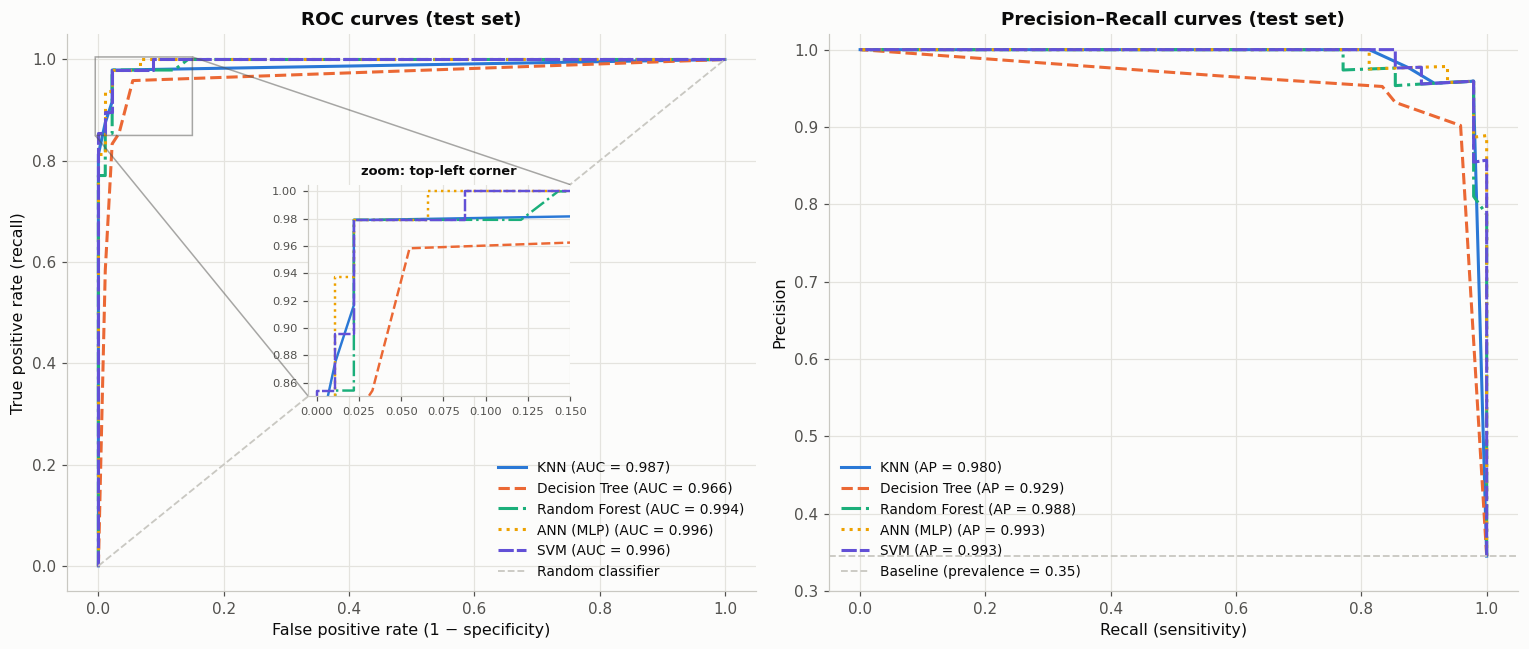

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name in MODEL_NAMES:
    s = positive_scores(final_models[name], X_test)
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], ls=MODEL_LINES[name], lw=2,
                 label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[1].plot(rec, prec, color=MODEL_COLORS[name], ls=MODEL_LINES[name], lw=2,
                 label=f"{name} (AP = {average_precision_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], color="#c9c8c2", ls="--", lw=1.2, label="Random classifier")
axes[0].set_title("ROC curves (test set)")
axes[0].set_xlabel("False positive rate (1 − specificity)")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].legend(loc="lower right", fontsize=9)
ins = axes[0].inset_axes([0.35, 0.35, 0.38, 0.38])
for name in MODEL_NAMES:
    s = positive_scores(final_models[name], X_test)
    fpr, tpr, _ = roc_curve(y_test, s)
    ins.plot(fpr, tpr, color=MODEL_COLORS[name], ls=MODEL_LINES[name], lw=1.6)
ins.set_xlim(-0.005, 0.15); ins.set_ylim(0.85, 1.005)
ins.set_title("zoom: top-left corner", fontsize=8.5)
ins.tick_params(labelsize=7.5)
axes[0].indicate_inset_zoom(ins, edgecolor=INK2)
axes[1].axhline(y_test.mean(), color="#c9c8c2", ls="--", lw=1.2, label=f"Baseline (prevalence = {y_test.mean():.2f})")
axes[1].set_title("Precision–Recall curves (test set)")
axes[1].set_xlabel("Recall (sensitivity)")
axes[1].set_ylabel("Precision")
axes[1].set_ylim(0.3, 1.02)
axes[1].legend(loc="lower left", fontsize=9)
fig.tight_layout()
save_fig(fig, "15_roc_pr_curves")
plt.show()

**Interpretation.** All curves hug the top-left (ROC) and top-right (PR) corners, far from the random baselines. The zoomed inset shows that ANN and SVM reach a true-positive rate of 1.0 at the lowest false-positive rate, which is why they have the highest AUC (0.996) and average precision (0.993). The Decision Tree's curve has few, large steps because a depth-4 tree outputs only a handful of distinct probabilities.

## 5.6 How certain are these test results? (bootstrap 95 % confidence intervals)

The test set has only 139 samples (48 malignant), so **one single misclassification changes recall by ≈ 2 percentage points**. Bootstrapping the test set (2,000 resamples) shows how much each metric could vary by chance.

In [42]:
def bootstrap_metrics(y_true, y_pred, scores, n_boot=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_pred, scores = map(np.asarray, (y_true, y_pred, scores))
    n = len(y_true)
    idx = rng.integers(0, n, size=(n_boot, n))
    Y, P, S = y_true[idx], y_pred[idx], scores[idx]
    tp = ((P == 1) & (Y == 1)).sum(1); fp = ((P == 1) & (Y == 0)).sum(1)
    fn = ((P == 0) & (Y == 1)).sum(1); tn = ((P == 0) & (Y == 0)).sum(1)
    ranks = stats.rankdata(S, axis=1)
    n_pos = Y.sum(1); n_neg = n - n_pos
    return pd.DataFrame({
        "Accuracy": (tp + tn) / n,
        "Precision": tp / np.maximum(tp + fp, 1),
        "Recall": tp / np.maximum(tp + fn, 1),
        "F1-score": 2 * tp / np.maximum(2 * tp + fp + fn, 1),
        "ROC-AUC": ((ranks * (Y == 1)).sum(1) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg),
    })

boot = {name: bootstrap_metrics(y_test, m.predict(X_test), positive_scores(m, X_test)) for name, m in final_models.items()}
ci_table = pd.DataFrame({
    name: {metric: f"{test_results.loc[name, metric]:.3f} [{b[metric].quantile(0.025):.3f}, {b[metric].quantile(0.975):.3f}]"
           for metric in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]}
    for name, b in boot.items()
}).T
ci_table.index.name = "Model  (point estimate [95% CI])"
ci_table

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model (point estimate [95% CI]),,,,,
KNN,"0.964 [0.928, 0.993]","0.957 [0.887, 1.000]","0.938 [0.857, 1.000]","0.947 [0.894, 0.989]","0.987 [0.960, 1.000]"
Decision Tree,"0.928 [0.885, 0.964]","0.932 [0.851, 1.000]","0.854 [0.750, 0.946]","0.891 [0.818, 0.951]","0.966 [0.927, 0.994]"
Random Forest,"0.964 [0.928, 0.993]","0.957 [0.887, 1.000]","0.938 [0.860, 1.000]","0.947 [0.892, 0.989]","0.994 [0.983, 1.000]"
ANN (MLP),"0.971 [0.942, 0.993]","0.978 [0.927, 1.000]","0.938 [0.860, 1.000]","0.957 [0.911, 0.991]","0.996 [0.989, 1.000]"
SVM,"0.971 [0.942, 0.993]","0.958 [0.891, 1.000]","0.958 [0.891, 1.000]","0.958 [0.911, 0.991]","0.996 [0.989, 1.000]"


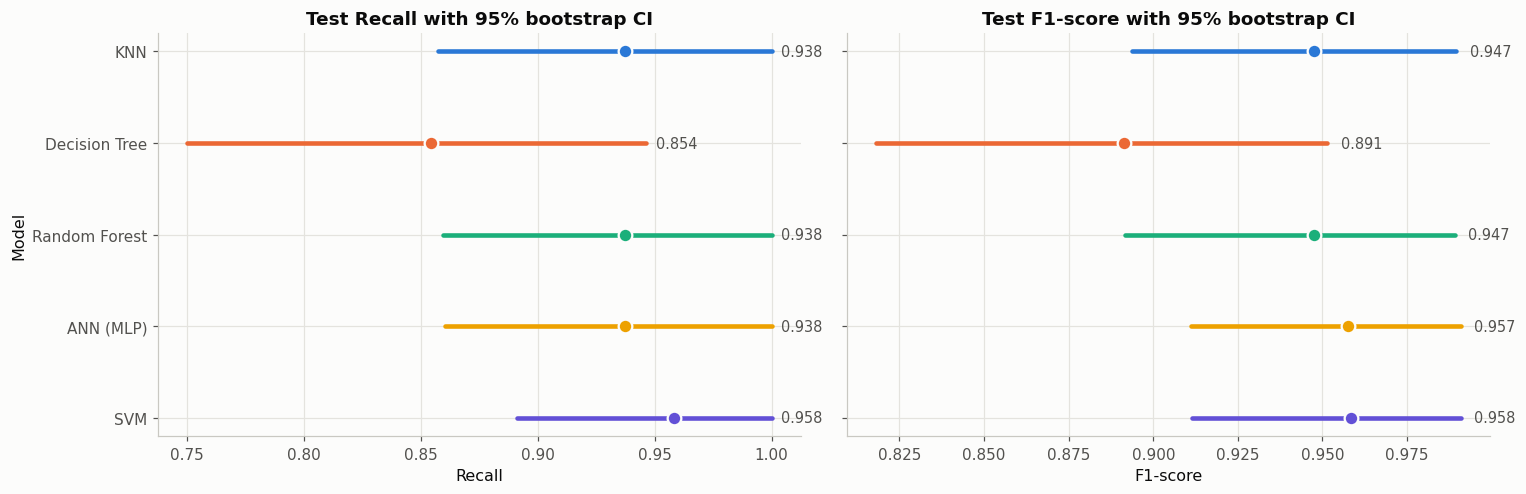

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, metric in zip(axes, ["Recall", "F1-score"]):
    for i, name in enumerate(MODEL_NAMES):
        b = boot[name][metric]
        point = test_results.loc[name, metric]
        lo_, hi_ = b.quantile(0.025), b.quantile(0.975)
        ax.plot([lo_, hi_], [i, i], color=MODEL_COLORS[name], lw=3, solid_capstyle="round")
        ax.scatter(point, i, color=MODEL_COLORS[name], s=80, zorder=5, edgecolor=SURFACE, linewidth=1.5)
        ax.text(hi_ + 0.004, i, f"{point:.3f}", va="center", fontsize=9.5, color=INK2)
    ax.set_yticks(range(5))
    ax.set_yticklabels(MODEL_NAMES)
    ax.set_title(f"Test {metric} with 95% bootstrap CI")
    ax.set_xlabel(metric)
    ax.set_ylabel("Model" if ax is axes[0] else "")
axes[0].invert_yaxis()   # y-axis is shared, so invert once
fig.tight_layout()
save_fig(fig, "16_bootstrap_ci")
plt.show()

In [44]:
def mcnemar_exact(y_true, pred_a, pred_b):
    """Exact McNemar test: do two classifiers make significantly different errors on the same samples?"""
    a_ok, b_ok = pred_a == y_true, pred_b == y_true
    n01, n10 = int(np.sum(a_ok & ~b_ok)), int(np.sum(~a_ok & b_ok))
    p = 1.0 if n01 + n10 == 0 else stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue
    return n01, n10, p

best_pred = final_models[best_name].predict(X_test)
mcn_rows = []
for name in MODEL_NAMES:
    if name == best_name:
        continue
    n01, n10, p = mcnemar_exact(y_test.to_numpy(), best_pred, final_models[name].predict(X_test))
    mcn_rows.append({"Comparison": f"{best_name} vs {name}", f"Only {best_name} correct": n01,
                     f"Only other correct": n10, "p-value": round(p, 4), "Significant at 5%?": "Yes" if p < 0.05 else "No"})
pd.DataFrame(mcn_rows).set_index("Comparison")

,Only ANN (MLP) correct,Only other correct,p-value,Significant at 5%?
Comparison,,,,
ANN (MLP) vs KNN,2,1,1.0000,No
ANN (MLP) vs Decision Tree,7,1,0.0703,No
ANN (MLP) vs Random Forest,2,1,1.0000,No
ANN (MLP) vs SVM,1,1,1.0000,No


## 5.7 Interpretation of the results and choice of the best model

**Reading the test results metric by metric**

* **Accuracy** — every model is far above the 65.5 % "always benign" baseline. ANN and SVM are joint-best with **97.1 %** (only 4 errors out of 139 patients).
* **Precision** — the ANN is the most precise (**97.8 %**): of the 46 samples it called malignant, only 1 was benign (1 false alarm).
* **Recall** — the SVM catches the most cancers (**95.8 %**, 2 missed). ANN, Random Forest and KNN miss 3 (93.8 %). The Decision Tree misses **7 of 48** cancers (85.4 %), which would be unacceptable clinically.
* **F1-score** — SVM (0.958) and ANN (0.957) are practically identical, followed by RF and KNN (0.947).
* **ROC-AUC** — ANN and SVM rank patients almost perfectly (**0.996**), RF 0.994, KNN 0.987. The shallow Decision Tree only produces a few distinct probability values, so its ROC curve is coarse (0.966).
* **Confusion matrices** show that the four leading models differ by only **one or two patients**.

**How certain are these differences?** The test set is small, so the bootstrap intervals are wide and overlap heavily (e.g. recall: ANN [0.86, 1.00] vs SVM [0.89, 1.00]). McNemar's test finds no significant difference between the ANN and any other model on the test set — ANN and SVM disagree on just two patients, each being right once. Even the Decision Tree's gap is only borderline on 139 samples (p ≈ 0.07), although cross-validation already showed it to be significantly worse.

**Best model: ANN (Multi-Layer Perceptron)** — justification

1. **Chosen without touching the test set.** It won the pre-declared rule on 50 cross-validation folds of the training data (highest mean F1 = 0.957 and highest recall among the tied contenders). Picking the model with the best *test* score would turn the test set into a validation set and bias the final estimate.
2. **Confirmed on unseen data.** On the test set it has the best (or joint-best) accuracy (97.1 %), precision (97.8 %), specificity (98.9 %) and ROC-AUC (0.996), and an F1 within 0.001 of the top.
3. **Best risk ranking.** Its top ROC-AUC means its probability scores separate malignant from benign samples best. That makes it the ideal model for a clinical **screening threshold**: in Part B, lowering the threshold (chosen on training data only) raises its recall to **97.9 % (1 missed cancer)** while precision stays at 95.9 % — better recall than any model at the default threshold.
4. **Produces probabilities directly**, which the demo app shows to the user.

**Honest caveat.** The SVM is statistically indistinguishable from the ANN (and missed one fewer cancer at the default threshold), so it would be an equally defensible choice — it is also simpler and faster. The Random Forest is the most stable model under nested CV (Part B). The clear, data-supported conclusions are: (1) **ANN, SVM, RF and KNN all reach ≈ 96–97 % accuracy and ROC-AUC ≥ 0.987**, (2) **the single Decision Tree is the weakest**, and (3) among the top group the **ANN is selected** by the transparent, leakage-free rule and its strong test performance confirms that choice.

---
# Part B — Beyond the Requirements

These extra analyses strengthen the conclusions: an unbiased performance estimate, model explainability, a clinically-motivated decision threshold, robustness checks, and a deployable model.

## B1. Nested cross-validation — an unbiased estimate of each algorithm

In Section 5.2 the hyperparameters were tuned and evaluated on the same training data, which is slightly optimistic. **Nested CV** removes that bias: an *outer* 5-fold loop holds out data for scoring, while an *inner* 5-fold grid search tunes hyperparameters on the remaining data only. The outer scores estimate how well *the whole procedure* (algorithm + tuning) generalises.

In [ ]:
if RUN_NESTED_CV:
    outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)
    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    nested_rows = []
    t0 = time.perf_counter()
    for name, (estimator, grid) in search_spaces.items():
        inner = GridSearchCV(make_pipeline(estimator), grid, scoring="f1", cv=inner_cv, n_jobs=-1)
        out = cross_validate(inner, X_train, y_train, cv=outer_cv, scoring=["f1", "recall", "roc_auc"])
        nested_rows.append({"Model": name,
                            "Nested F1": f"{out['test_f1'].mean():.4f} ± {out['test_f1'].std():.4f}",
                            "Nested Recall": f"{out['test_recall'].mean():.4f} ± {out['test_recall'].std():.4f}",
                            "Nested ROC-AUC": f"{out['test_roc_auc'].mean():.4f} ± {out['test_roc_auc'].std():.4f}",
                            "_f1": out["test_f1"].mean()})
    nested_table = pd.DataFrame(nested_rows).set_index("Model").sort_values("_f1", ascending=False).drop(columns="_f1")
    print(f"Nested CV finished in {time.perf_counter() - t0:.0f} s")
    display(nested_table)
else:
    print("Nested CV skipped (RUN_NESTED_CV = False).")

**Interpretation.** Nested scores are slightly lower than the non-nested CV scores of Section 5.2 — exactly as expected, because they remove the optimism of tuning and evaluating on the same folds. The ANN loses the most (0.957 → 0.948 F1): its larger search space leaves more room for lucky hyperparameter choices, although it still has the **best nested ROC-AUC (0.995)**. The **Random Forest is the most robust procedure** (nested F1 0.960, recall 0.990). Within the top four the ranking changes with the protocol and all differences are smaller than one standard deviation (≈ 0.02), while the Decision Tree is last under every protocol. The unbiased generalisation estimate (F1 ≈ 0.95–0.96) matches the test-set results, which confirms that the test performance is not a lucky split.

## B2. Explainability — which features drive the predictions?

**Permutation importance** measures how much the selected model's ROC-AUC drops on the test set when one feature's values are randomly shuffled (breaking its link with the target). It works for *any* model, unlike tree-specific importances. We compare it with the Random Forest's built-in impurity importance.

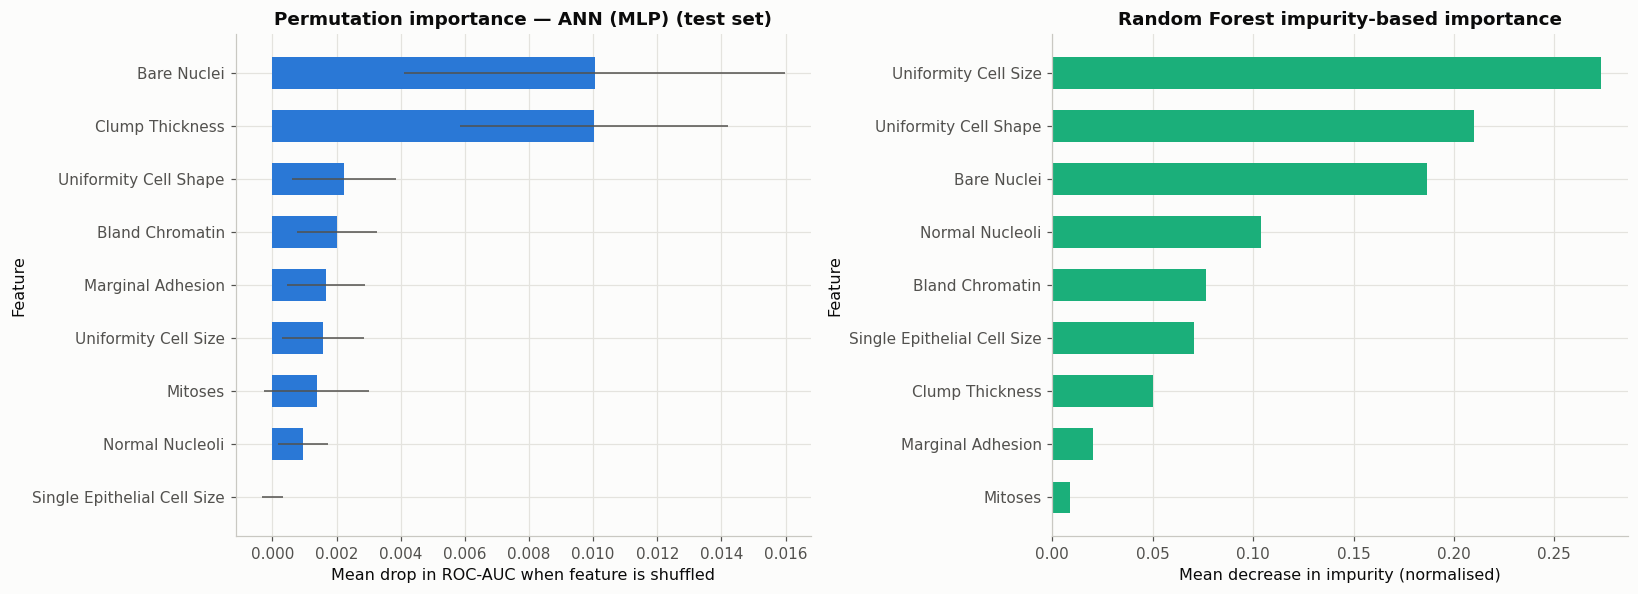

In [ ]:
best_model = final_models[best_name]
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=50, random_state=RANDOM_STATE, n_jobs=-1)
perm_df = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=FEATURES).sort_values("mean")
rf_imp = pd.Series(final_models["Random Forest"].named_steps["model"].feature_importances_, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh([LABELS[f] for f in perm_df.index], perm_df["mean"], xerr=perm_df["std"], color=BENIGN_C,
             height=0.6, error_kw={"ecolor": INK2, "lw": 1})
axes[0].set_title(f"Permutation importance — {best_name} (test set)")
axes[0].set_xlabel("Mean drop in ROC-AUC when feature is shuffled")
axes[0].set_ylabel("Feature")
axes[1].barh([LABELS[f] for f in rf_imp.index], rf_imp.values, color="#1baf7a", height=0.6)
axes[1].set_title("Random Forest impurity-based importance")
axes[1].set_xlabel("Mean decrease in impurity (normalised)")
axes[1].set_ylabel("Feature")
fig.tight_layout()
save_fig(fig, "17_feature_importance")
plt.show()

**Interpretation.** Both methods agree that `Bare Nuclei` is a key driver and that `Mitoses` contributes least, consistent with the EDA. They disagree on the uniformity features, and the reason is the multicollinearity found in the heatmap: `Uniformity of Cell Size` and `Shape` are correlated at ρ = 0.89, so when one of them is shuffled the ANN can still rely on the other, and its *individual* permutation importance looks small. The Random Forest's impurity importance instead credits whichever correlated feature its trees happened to split on first. The absolute drops are small (≤ 0.01 ROC-AUC) because the information is spread redundantly across features and the model is near-perfect — no single feature is indispensable.

## B3. Clinical decision threshold — a "screening mode"

By default a model predicts *malignant* when its score passes 0.5 (probability) or 0 (SVM margin). In screening, missing a cancer is far worse than a false alarm, so we can **lower the threshold** to raise recall. The threshold is chosen **on the training set only**, using out-of-fold predictions, by maximising the **F2-score** (an F-score that weights recall twice as much as precision). Only then is it applied to the test set.

In [ ]:
method = "predict_proba" if hasattr(best_model, "predict_proba") else "decision_function"
oof = cross_val_predict(clone(best_model), X_train, y_train, cv=CV, method=method, n_jobs=-1)
oof_scores = oof[:, 1] if oof.ndim == 2 else oof
default_threshold = 0.5 if method == "predict_proba" else 0.0

prec, rec, thr = precision_recall_curve(y_train, oof_scores)
prec, rec = prec[:-1], rec[:-1]
f2 = 5 * prec * rec / np.maximum(4 * prec + rec, 1e-12)
best_i = int(np.argmax(f2))
screen_threshold = float(thr[best_i])
print(f"Score type: {method}")
print(f"Default threshold : {default_threshold:.3f}")
print(f"F2-optimal threshold (chosen on training OOF predictions): {screen_threshold:.3f}")

test_scores = positive_scores(best_model, X_test)
rows = {}
for label, t in [("Default threshold", default_threshold), ("Screening threshold", screen_threshold)]:
    pred = (test_scores >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows[label] = {"Threshold": round(t, 3), "Recall": recall_score(y_test, pred), "Precision": precision_score(y_test, pred),
                   "F1-score": f1_score(y_test, pred), "Specificity": tn / (tn + fp), "Missed cancers (FN)": fn, "False alarms (FP)": fp}
threshold_table = pd.DataFrame(rows).T
threshold_table

Score type: predict_proba
Default threshold : 0.500
F2-optimal threshold (chosen on training OOF predictions): 0.177


,Threshold,Recall,Precision,F1-score,Specificity,Missed cancers (FN),False alarms (FP)
Default threshold,0.500,0.937500,0.978261,0.957447,0.989011,3.0,1.0
Screening threshold,0.177,0.979167,0.959184,0.969072,0.978022,1.0,2.0


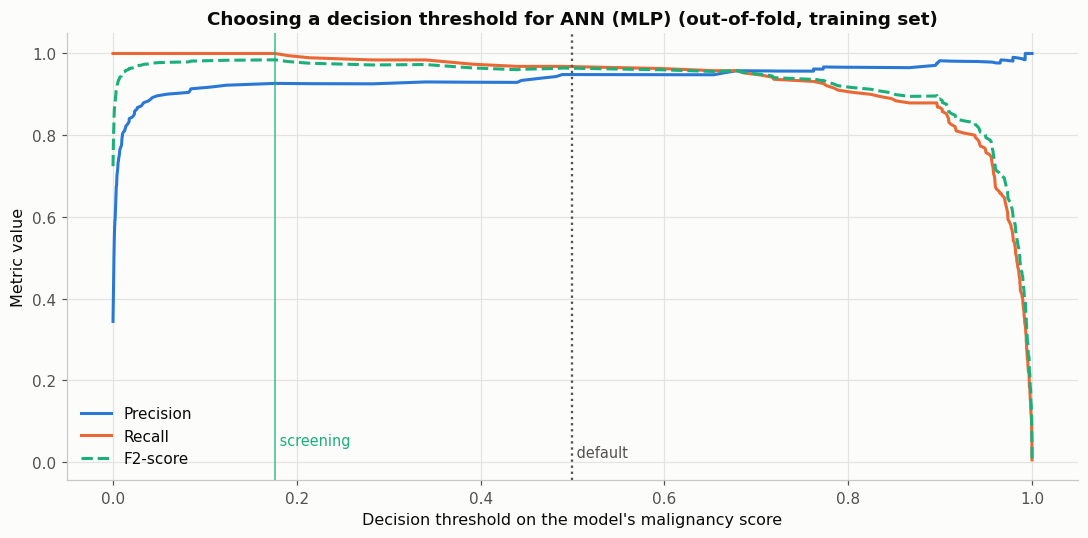

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thr, prec, color=BENIGN_C, label="Precision")
ax.plot(thr, rec, color=MALIGNANT_C, label="Recall")
ax.plot(thr, f2, color="#1baf7a", ls="--", label="F2-score")
ax.axvline(default_threshold, color=INK2, ls=":", lw=1.5)
ax.axvline(screen_threshold, color="#1baf7a", ls="-", lw=1.2, alpha=0.7)
ymin = min(prec.min(), rec.min())
ax.text(default_threshold, ymin, " default", color=INK2, fontsize=9.5, va="bottom")
ax.text(screen_threshold, ymin + 0.03, " screening", color="#1baf7a", fontsize=9.5, va="bottom")
ax.set_title(f"Choosing a decision threshold for {best_name} (out-of-fold, training set)")
ax.set_xlabel("Decision threshold on the model's malignancy score")
ax.set_ylabel("Metric value")
ax.legend(loc="lower left")
fig.tight_layout()
save_fig(fig, "18_threshold_tuning")
plt.show()

**Interpretation.** Lowering the decision threshold from 0.50 to **≈ 0.18** (chosen on training data only) changes the test results from **3 missed cancers + 1 false alarm** to **1 missed cancer + 2 false alarms**: recall rises from 93.8 % to **97.9 %**, precision falls only slightly (97.8 % → 95.9 %), and F1 even improves (0.957 → 0.969). Trading one extra follow-up test for two detected cancers is a clinically sensible trade — this is how the model would be deployed in a screening setting. The final threshold in a real hospital would be agreed with clinicians based on the actual costs of each error.

## B4. Learning curve — would more data help?

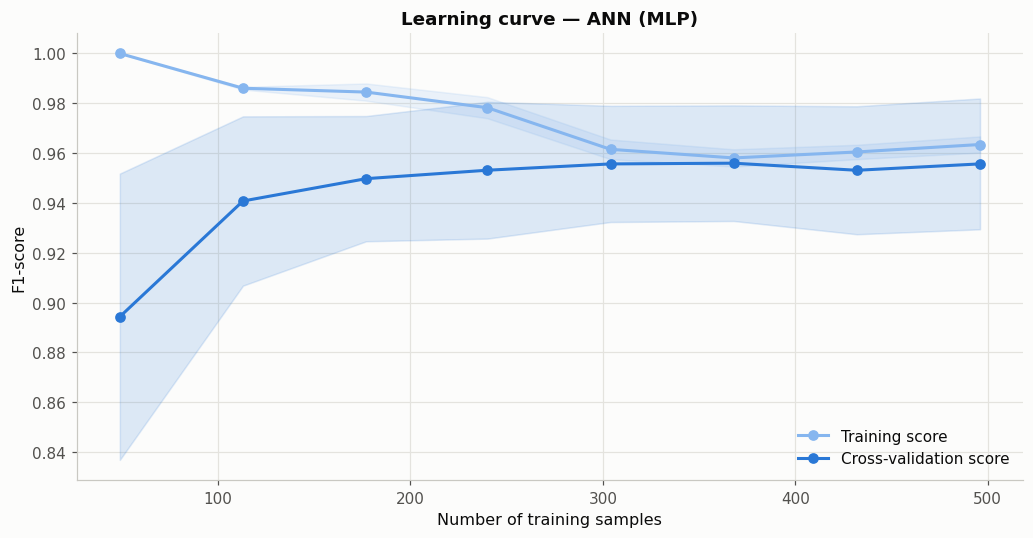

In [ ]:
sizes, tr_scores, val_scores = learning_curve(clone(best_model), X_train, y_train, cv=CV, scoring="f1",
                                              train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(9.5, 5))
for scores_, color, label in [(tr_scores, "#86b6ef", "Training score"), (val_scores, BENIGN_C, "Cross-validation score")]:
    m, s = scores_.mean(1), scores_.std(1)
    ax.plot(sizes, m, marker="o", color=color, label=label)
    ax.fill_between(sizes, m - s, m + s, color=color, alpha=0.15)
ax.set_title(f"Learning curve — {best_name}")
ax.set_xlabel("Number of training samples")
ax.set_ylabel("F1-score")
ax.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "19_learning_curve")
plt.show()

**Interpretation.** The cross-validation score climbs quickly and **plateaus at ≈ 0.955 after ~300 samples**, and the gap between training and CV curves becomes small (< 0.01). The model is neither overfitting nor starved of data: collecting *more samples of the same nine features* would bring little gain. Further improvement would need *richer information* — e.g. the 30 continuous nuclear measurements of the related Wisconsin *Diagnostic* dataset, or imaging.

## B5. Robustness check — do repeated feature profiles inflate the scores?

Because many different patients share identical 9-feature profiles, some test samples have an exact "twin" in the training set. If the models were just memorising profiles, they would look much better on twins than on unseen profiles. We check this in two ways.

In [ ]:
train_keys = set(map(tuple, X_train.fillna(-1).astype(int).to_numpy()))
has_twin = np.array([tuple(r) in train_keys for r in X_test.fillna(-1).astype(int).to_numpy()])
print(f"Test samples whose exact profile also appears in training: {has_twin.sum()} of {len(X_test)} "
      f"({has_twin.mean():.0%}) — mostly benign: {y_test[has_twin].eq(0).mean():.0%} of them")

novel = ~has_twin
rob_rows = {}
for name, m in final_models.items():
    pred = m.predict(X_test)
    rob_rows[name] = {
        "Accuracy (all test)": accuracy_score(y_test, pred),
        "Accuracy (novel profiles only)": accuracy_score(y_test[novel], pred[novel]),
        "F1 (novel profiles only)": f1_score(y_test[novel], pred[novel]),
    }

# Second check: re-run the repeated CV after removing ALL duplicate profiles from the training data
dedup_mask = ~X_train.fillna(-1).duplicated()
X_tr_u, y_tr_u = X_train[dedup_mask], y_train[dedup_mask]
for name, pipe in tuned_pipelines.items():
    s = cross_val_score(pipe, X_tr_u, y_tr_u, cv=RCV, scoring="f1", n_jobs=-1)
    rob_rows[name]["CV F1 (original train)"] = rcv_scores[name]["f1"].mean()
    rob_rows[name]["CV F1 (unique profiles only)"] = s.mean()
print(f"Training rows with a unique profile: {dedup_mask.sum()} of {len(X_train)}")
pd.DataFrame(rob_rows).T.round(4)

Test samples whose exact profile also appears in training: 57 of 139 (41%) — mostly benign: 100% of them
Training rows with a unique profile: 382 of 552


,Accuracy (all test),Accuracy (novel profiles only),F1 (novel profiles only),CV F1 (original train),CV F1 (unique profiles only)
KNN,0.9640,0.9390,0.9474,0.9537,0.9512
Decision Tree,0.9281,0.8780,0.8913,0.9275,0.9153
Random Forest,0.9640,0.9390,0.9474,0.9543,0.9548
ANN (MLP),0.9712,0.9512,0.9574,0.9565,0.9519
SVM,0.9712,0.9512,0.9583,0.9548,0.9469


**Interpretation.** 57 of the 139 test samples (41 %) have an identical twin in the training set — and **all of them are benign** (mostly the "everything scores 1" profile). Every malignant test sample is a profile the model has never seen, so the malignant-class metrics (recall, F1) are not inflated by memorisation at all: for the ANN, F1 on novel profiles (0.957) equals its overall F1. Accuracy on novel profiles is a little lower (95.1 % vs 97.1 %) simply because the twins are the easiest benign cases. Re-running cross-validation after removing all duplicate profiles from the training data barely changes F1 (ANN 0.957 → 0.952, Random Forest 0.954 → 0.955). **Conclusion: keeping the repeated profiles was safe; the results are not an artefact of duplicates.**

## B6. Error analysis — which cases does the best model get wrong?

In [ ]:
errors = X_test.copy()
errors["True"] = y_test.map({0: "Benign", 1: "Malignant"})
errors["Predicted"] = pd.Series(best_model.predict(X_test), index=X_test.index).map({0: "Benign", 1: "Malignant"})
errors["Risk score"] = positive_scores(best_model, X_test).round(3)
errors = errors[errors["True"] != errors["Predicted"]]
print(f"{best_name} misclassified {len(errors)} of {len(X_test)} test samples.")
errors

ANN (MLP) misclassified 4 of 139 test samples.


,Clump_Thickness,Uniformity_Cell_Size,Uniformity_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,True,Predicted,Risk score
43,5,6,5,6,10,1.0,3,1,1,Malignant,Benign,0.387
12,5,3,3,3,2,3.0,4,4,1,Malignant,Benign,0.327
1,5,4,4,5,7,10.0,3,2,1,Benign,Malignant,0.902
221,4,1,1,3,1,5.0,2,1,1,Malignant,Benign,0.025


**Interpretation.** Of the 4 errors, 3 are missed cancers and 1 is a false alarm.
* Two missed cancers have **mid-range scores (3–6) and risk scores of 0.33–0.39** — genuinely borderline cases. These are exactly the two that the screening threshold (≈ 0.18) recovers.
* One missed cancer has an **almost entirely normal profile** (most scores 1–3) and a risk of only 0.03; it cannot be flagged from these nine features without causing many false alarms — in practice such cases are caught by imaging or biopsy.
* The false alarm has **`Bare Nuclei` = 10 and enlarged epithelial cells** — it looks malignant under the microscope, so the model's mistake mirrors what a cytologist might also find suspicious.

## B7. Save the final models and results

In [ ]:
# Models used by the Streamlit demo app (app/app.py). SVM gets probability calibration so every model outputs a probability.
app_models = {}
for name, est in final_models.items():
    if not hasattr(est, "predict_proba"):
        est = CalibratedClassifierCV(clone(est), method="sigmoid", cv=5).fit(X_train, y_train)
    app_models[name] = est

joblib.dump({"models": app_models, "best_name": best_name, "features": FEATURES,
             "sklearn_version": sklearn.__version__}, MODEL_DIR / "models.joblib")

summary = {
    "best_model": best_name,
    "selection_rule": "highest mean F1 in 10x5 repeated stratified CV on training set; ties (<0.005) broken by recall, then ROC-AUC",
    "best_params": {n: {k.replace("model__", ""): (v if not isinstance(v, tuple) else list(v)) for k, v in gs.best_params_.items()}
                    for n, gs in searches.items()},
    "test_metrics": {n: {k: (float(v) if k not in ("TP", "TN", "FP", "FN") else int(v)) for k, v in row.items()}
                     for n, row in test_results.to_dict(orient="index").items()},
    "cv_f1_mean": {n: float(rcv_scores[n]["f1"].mean()) for n in MODEL_NAMES},
    "screening_threshold": {"model": best_name, "score_type": method, "threshold": screen_threshold},
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
}
(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print("Saved: models/models.joblib, results/model_comparison.csv, results/summary.json")
print(f"Figures saved in {FIG_DIR}/:", len(list(FIG_DIR.glob('*.png'))), "PNG files")

Saved: models/models.joblib, results/model_comparison.csv, results/summary.json
Figures saved in figures/: 19 PNG files


---
# Conclusion & Future Work

### What we did
1. **Explored** the Breast Cancer Wisconsin (Original) data and found three hidden data-quality issues: missing values disguised as `?`, 8 exact duplicate records, and an identifier column with no predictive value.
2. **Preprocessed without leakage**: stratified 80/20 split, median imputation and standardization fitted on training data only and wrapped in a `Pipeline` so they are re-fitted inside every CV fold.
3. **Analysed** the data visually: malignant samples score higher on every feature; the uniformity features and `Bare Nuclei` are the strongest predictors; the classes are almost linearly separable (PC1 = 66 % of variance).
4. **Tuned five algorithms** with 10-fold stratified grid search (350 configurations in total) optimising F1 for the malignant class.
5. **Selected the best model on training data only** with a pre-declared rule, then evaluated all models once on the untouched test set with five required metrics, confusion matrices, ROC/PR curves, bootstrap confidence intervals and statistical tests.

### Key results

| | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **★ ANN (MLP) — selected** | **0.971** | **0.978** | 0.938 | 0.957 | **0.996** |
| ANN with screening threshold (≈ 0.18) | 0.978 | 0.959 | **0.979** | **0.969** | 0.996 |

* **ANN, SVM, Random Forest and KNN** all reach ≈ 96–97 % accuracy with ROC-AUC ≥ 0.987; their differences (1–2 patients) are not statistically significant.
* The **Decision Tree** is the most interpretable but clearly the weakest (7 missed cancers).
* The **ANN** is the best overall: selected by the leakage-free rule, joint-best accuracy, best precision and ROC-AUC on the test set, and — with a recall-oriented threshold — only **1 missed cancer out of 48**.
* Robustness checks (nested CV, duplicate-profile analysis, learning curve) confirm that the performance is genuine and not an artefact of the split or of repeated profiles.

### Limitations
* The dataset is small (699 samples), collected 1989–1991 at a single hospital; results may not transfer to other populations or laboratories.
* With 139 test samples, one patient changes recall by ≈ 2 points — confidence intervals are wide.
* The features are **subjective scores** assigned by a cytologist, so they vary between observers.

### Possible future improvements
1. **External validation** on an independent dataset (e.g. the Wisconsin *Diagnostic* dataset with 30 continuous image-derived features).
2. **Ensembles / stacking** of the complementary top models (ANN + SVM + Random Forest), and **gradient boosting** (XGBoost, LightGBM).
3. **Cost-sensitive learning** with an explicit cost for a missed cancer, and threshold selection agreed with clinicians.
4. **Probability calibration analysis** (reliability curves, Brier score) so the predicted risks can be trusted as real probabilities.
5. **Per-patient explanations** with SHAP values, and a *missing-value indicator* feature.
6. **Deployment**: the included Streamlit app (`app/app.py`) is a first step; a real system would add input validation, monitoring and a regulatory review.

> ⚠️ This project is an educational exercise and not a medical device.